# Compact Object Coalescence Rates — Figure Notebook

Plots merger rate density estimates for BH-BH, NS-BH, and NS-NS binaries  
from `Data_Mandel_and_Broekgaarden_2026/` (tidy long-format CSVs).

**Data schema** — one row per rate estimate:

| column | description |
|---|---|
| `compact_object_type` | `"BH-BH"` / `"NS-BH"` / `"NS-NS"` |
| `formation_channel` | e.g. `"isolated-binary-evolution"` |
| `study_key` | machine-readable unique key per (DCO type, study) |
| `label` | display label, e.g. `"Rodriguez et al. (2015)"` |
| `first_author`, `year`, `month`, `ads_url`, `arxiv_url`, `code` | bibliographic info |
| `plotting_style` | `"range"` / `"credible_interval"` / `"single_value"` / `"upper_limit"` / `"lower_limit"` / `"range_with_upper_limit"` / `"range_with_lower_limit"` |
| `rate_Gpc3yr` | merger rate in Gpc⁻³ yr⁻¹ |
| `rate_type` | `"lower"` / `"upper"` / `"central"` / `"single"` / empty |
| `submodel` | model variant label (e.g. `"fiducial"`); NaN if unlabelled |
| `notes` | raw notes |
| `superseded` | `True` if a newer measurement supersedes this entry (drawn at 30 % opacity by default) |
| `sigma_kick`, `alpha_CE`, `beta_MT`, … | physics parameters (isolated-binary-evolution only) |

**Superseded flag usage:**
```python
make_figure(..., include_superseded=True, dim_superseded=True)   # show old rates faded (default)
make_figure(..., include_superseded=False)                        # hide old rates entirely
make_figure(..., dim_superseded=False)                            # show all at full opacity
```


## 1 — Imports & matplotlib style

In [1]:
from pathlib import Path
from typing import Literal

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import rc, rcParams
from matplotlib.ticker import AutoMinorLocator

from __future__ import annotations # for python <3.10 

# just to make the cells appear wider: comment these lines if needed. 
from IPython.display import display, HTML
display(HTML("<style>.container { width:100% !important; }</style>"))

rc("font", family="serif", weight="bold")
rc("text", usetex=True)
rcParams["text.latex.preamble"] = r"\usepackage{amsmath}" + "\n" + r"\boldmath"
rc("axes", linewidth=2)
rcParams.update({
    "xtick.major.size": 12, "ytick.major.size": 12,
    "xtick.minor.size": 8,  "ytick.minor.size": 8,
    "font.weight": "bold",
})

FONTSIZE = 24

# path to the restructured data directory
DATA_DIR = Path("../data")

# figures are saved here (created automatically if it doesn't exist)
FIGURES_DIR = Path("../figures")
FIGURES_DIR.mkdir(exist_ok=True)

gray_color = 'darkgrey'


## 2 — Colour palette & channel labels

In [2]:
# Formation channels in display order
ALL_CHANNELS = [
    "observations-GWs",
    "observations-sGRBs",
    "observations-kilonovae",
    "observations-pulsars",
    "isolated-binary-evolution",
    "CHE",
    "population-III",
    "flybys",
    "triples",
    "globular-clusters",
    "nuclear-clusters",
    "young-stellar-clusters",
    "primordial",
]

_palette = ["orangered"] + list(sns.color_palette("husl", len(ALL_CHANNELS) - 1))
CHANNEL_COLOR: dict[str, tuple] = dict(zip(ALL_CHANNELS, _palette))

CHANNEL_LABEL: dict[str, str] = {
    "observations-GWs":          r"Gravitational waves",
    "observations-sGRBs":        r"Short gamma-ray bursts",
    "observations-kilonovae":    r"Kilonovae",
    "observations-pulsars":      r"Galactic pulsar binaries",
    "isolated-binary-evolution": r"Isolated binary evolution",
    "CHE":                       r"Chemically homogeneous evolution",
    "population-III":            r"Population III stars",
    "flybys":                    r"Wide isolated binaries $+$ flybys",
    "triples":                   r"Triples / Multiples",
    "globular-clusters":         r"Globular clusters",
    "nuclear-clusters":          r"Nuclear star clusters",
    "young-stellar-clusters":    r"Young / Open star clusters",
    "primordial":                r"Primordial",
}

DCO_LABEL = {"BH-BH": "BH-BH", "NS-BH": "NS-BH", "NS-NS": "NS-NS"}

## 3 — Data loading

In [3]:
def load_channel(channel: str, data_dir: Path = DATA_DIR) -> pd.DataFrame:
    """Load one formation-channel CSV."""
    return pd.read_csv(
        data_dir / f"{channel}.csv",
        dtype={"year": "Int64", "month": "Int64"}, engine='python' 
    )


def load_all(data_dir: Path = DATA_DIR) -> pd.DataFrame:
    """Load and concatenate all formation-channel CSVs."""
    return pd.concat(
        [pd.read_csv(p, dtype={"year": "Int64", "month": "Int64"}, engine='python')
         for p in sorted(data_dir.glob("*.csv"))],
        ignore_index=True,
    )


# Quick sanity check
df_all = load_all()
print(f"Total rows: {len(df_all)}")
print(df_all.groupby(["compact_object_type", "formation_channel"]).size().to_string())

Total rows: 13097
compact_object_type  formation_channel        
BH-BH                CHE                            29
                     flybys                          2
                     globular-cluster                9
                     globular-clusters              61
                     isolated-binary-evolution    1578
                     nuclear-cluster                 9
                     nuclear-clusters               77
                     observations-GWs                9
                     population-III                 13
                     primordial                      6
                     triples                        43
                     young-cluster                   9
                     young-stellar-clusters         32
NS-BH                CHE                             2
                     flybys                          1
                     globular-clusters               9
                     isolated-binary-evolution    1092


## 4 — Drawing helpers

### `plotting_style` → visual encoding

| `plotting_style` | visual |
|---|---|
| `range` | horizontal bar min→max, all values as dots |
| `credible_interval` | same bar, central value marked in black |
| `single_value` | single dot |
| `upper_limit` | downward-triangle (▽) at maximum value |
| `lower_limit` | upward-triangle (△) at minimum value |
| `range_with_upper_limit` | range bar + ▽ at max |
| `range_with_lower_limit` | range bar + △ at min |

In [4]:
def _rates(group: pd.DataFrame) -> np.ndarray:
    """Sorted, non-NaN rate values for one study group."""
    return np.sort(group["rate_Gpc3yr"].dropna().to_numpy())


def draw_study(
    ax: plt.Axes,
    group: pd.DataFrame,
    y: float,
    color,
    alpha: float = 1.0,
    gwtc5_upper: float | None = None,
    highlight_below_gwtc5: bool = False,
) -> None:
    """
    Draw one study at vertical position `y`.

    If highlight_below_gwtc5=True:
    - points with rate <= GWTC-5 upper rate keep the channel color
    - points with rate > GWTC-5 upper rate become gray
    - the range line is split at GWTC-5 upper rate
    """
    ps = group["plotting_style"].iloc[0]
    rates = _rates(group)
    if len(rates) == 0:
        return

    LWIDTH = 5.5
    DOT_S  = 125
    LIM_S  = 400
    gray_color = "lightgray"

    use_gwtc5_highlight = highlight_below_gwtc5 and (gwtc5_upper is not None)

    if use_gwtc5_highlight:
        point_colors = [
            color if r <= gwtc5_upper else gray_color
            for r in rates
        ]
    else:
        point_colors = [color] * len(rates)

    if ps == "single_value":
        ax.scatter(
            rates[0], y,
            s=DOT_S,
            c=[point_colors[0]],
            zorder=100,
            marker="o",
            alpha=alpha,
        )
        return

    if ps == "upper_limit":
        ax.scatter(
            rates[-1], y,
            s=LIM_S,
            c="k",
            zorder=1e6,
            marker=4,
            alpha=alpha,
        )
        return

    if ps == "lower_limit":
        ax.scatter(
            rates[0], y,
            s=LIM_S,
            c="k",
            zorder=1e6,
            marker=5,
            alpha=alpha,
        )
        return

    rmin = rates.min()
    rmax = rates.max()

    # Draw range line, optionally split at GWTC-5 upper rate
    if use_gwtc5_highlight:
        if rmin <= gwtc5_upper:
            ax.plot(
                [rmin, min(rmax, gwtc5_upper)],
                [y, y],
                color=color,
                lw=LWIDTH,
                alpha=alpha,
                zorder=5,
                solid_capstyle="round",
            )

        if rmax > gwtc5_upper:
            ax.plot(
                [max(rmin, gwtc5_upper), rmax],
                [y, y],
                color=gray_color,
                lw=LWIDTH,
                alpha=alpha,
                zorder=5,
                solid_capstyle="round",
            )
    else:
        ax.plot(
            [rmin, rmax],
            [y, y],
            color=color,
            lw=LWIDTH,
            alpha=alpha,
            zorder=5,
            solid_capstyle="round",
        )

    # Individual rates
    ax.scatter(
        rates,
        np.full_like(rates, y),
        s=DOT_S,
        c=point_colors,
        zorder=100,
        marker="o",
        alpha=alpha,
    )

    if ps == "range_with_upper_limit":
        ax.scatter(
            rates.max(), y,
            s=LIM_S,
            c="k",
            zorder=1e6,
            marker=4,
            alpha=alpha,
        )

    elif ps == "range_with_lower_limit":
        ax.scatter(
            rates.min(), y,
            s=LIM_S,
            c="k",
            zorder=1e6,
            marker=5,
            alpha=alpha,
        )

    elif ps == "credible_interval":
        central = group.loc[group["rate_type"] == "central", "rate_Gpc3yr"]
        if not central.empty:
            central_rate = central.iloc[0]

            if use_gwtc5_highlight:
                central_color = color if central_rate <= gwtc5_upper else gray_color
            else:
                central_color = "k"

            ax.scatter(
                central_rate,
                y,
                s=DOT_S,
                c=central_color,
                zorder=1e6,
                marker="o",
                alpha=alpha,
            )


def draw_study_label(
    ax: plt.Axes,
    group: pd.DataFrame,
    y: float,
    fontsize: float = FONTSIZE - 5,
    alpha: float = 1.0,
    code_label=False,
) -> None:
    """Place the study label text left or right of the data point(s)."""
    rates = _rates(group)
    if len(rates) == 0:
        return
    label = group["label"].iloc[0].replace("&", r"\&") 
    
    if code_label==True:
        code  = group["code"].iloc[0]
#         label = f"{label} [{code}]"    
        if code.lower() == "brussels":
            label = f"{label}\n[{code}]"
        else:
            label = f"{label} [{code}]"
    
    
    if rates.min() > 2e-2:
        ax.text(rates.min() / 1.25, y, label, ha="right", va="center",
                fontsize=fontsize, alpha=alpha)
    elif rates.max() > 1e-3:
        ax.text(rates.max() * 1.25, y, label, ha="left",  va="center",
                fontsize=fontsize, alpha=alpha)
    else:
        ax.text(1e-3 * 1.35,        y, label, ha="left",  va="center",
                fontsize=fontsize, alpha=alpha)


## 5 — Axes setup

In [5]:
from matplotlib.ticker import LogLocator
import numpy as np

def setup_axes(
    ax: plt.Axes,
    dco_type: str,
    n_rows: int,
    n_channels: int,
) -> None:
    """Apply log scale, limits, labels, and grid lines to `ax`."""
    xmin, xmax = 1e-3, 1e5
    ax.set_xscale("log")
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(-(n_rows + 2 * n_channels) - 0.5, 0.5)
    ax.set_yticks([])

    dco_str = DCO_LABEL[dco_type].replace("-", r"\text{-}")
    xlabel = (
        r"$\mathrm{Local}\ \mathbf{" + dco_str
        + r"}\ \mathbf{merger\ rate\ density}\ [\mathrm{Gpc}^{-3}\ \mathrm{yr}^{-1}]$"
    )
    ax.set_xlabel(xlabel, fontsize=FONTSIZE + 6, labelpad=4)

    # Major ticks at 10^n
    ax.xaxis.set_major_locator(LogLocator(base=10.0))

    # Minor ticks at 2,...,9 × 10^n
    ax.xaxis.set_minor_locator(
        LogLocator(base=10.0, subs=np.arange(2, 10))
    )

    for tick in ax.xaxis.get_major_ticks():
        tick.label1.set_fontsize(FONTSIZE)

    ax.tick_params(which="major", length=10, width=1.5)
    ax.tick_params(which="minor", length=5, width=1.5)

    for spine in ax.spines.values():
        spine.set_linewidth(1.2)

    # Grid lines
    ax.grid(
        which="major",
        axis="x",
        color="gray",
        ls=":",
        lw=1.5,
        zorder=0,
    )

    ax.grid(
        which="minor",
        axis="x",
        color="gray",
        ls=":",
        lw=0.7,
        alpha=0.4,
        zorder=0,
    )

    # mirrored x-axis label on top
    ax2 = ax.twiny()
    ax2.set_xscale("log")
    ax2.set_xlim(xmin, xmax)
    ax2.set_xlabel(xlabel, fontsize=FONTSIZE + 6, labelpad=20)
    
    ax2.xaxis.set_major_locator(LogLocator(base=10.0))
    ax2.xaxis.set_minor_locator(LogLocator(base=10.0, subs=np.arange(2, 10)))
    ax2.tick_params(which="minor", length=5, width=1.5)

    for tick in ax2.xaxis.get_major_ticks():
        tick.label2.set_fontsize(FONTSIZE)

    ax2.tick_params(which="major", length=10, width=1.5)

## 6 — Main figure function

In [6]:
def make_figure(
    dco_type: Literal["BH-BH", "NS-BH", "NS-NS"],
    channels: list[str],
    data_dir: Path = DATA_DIR,
    order: Literal["year", "max_rate"] = "year",
    fig_width: float = 20,
    save_path: str | None = None,
    include_superseded: bool = True,
    dim_superseded: bool = True,
    superseded_alpha: float = 0.30,
    highlight_below_gwtc5: bool = False,
    highlight_channels: list[str] | None = None,
    code_label: bool = False,
) -> tuple[plt.Figure, plt.Axes]:
    """
    Build a horizontal merger-rate-density figure for `dco_type`.

    Parameters
    ----------
    dco_type           : "BH-BH", "NS-BH", or "NS-NS"
    channels           : formation channels to include, in display order
    data_dir           : path to Data_Mandel_and_Broekgaarden_2026/
    order              : sort studies by "year" or "max_rate"
    fig_width          : figure width in inches
    save_path          : if given, save as <save_path>.png and <save_path>.pdf
    include_superseded : if False, drop studies marked superseded=True entirely
    dim_superseded     : if True (and include_superseded), draw superseded
                         studies at superseded_alpha opacity
    superseded_alpha   : alpha for superseded studies (default 0.30)
    """
    # ── Load & filter data ───────────────────────────────────────────────
    frames = []
    for ch in channels:
        try:
            df_ch = load_channel(ch, data_dir)
        except FileNotFoundError:
            print(f"WARNING: {ch}.csv not found — skipping.")
            continue
        frames.append(df_ch[df_ch["compact_object_type"] == dco_type])

    if not frames:
        raise ValueError("No data found for the requested channels / DCO type.")
    df = pd.concat(frames, ignore_index=True)

    # Normalise superseded column (absent in channels that don't have it)
    if "superseded" not in df.columns:
        df["superseded"] = False
    df["superseded"] = df["superseded"].astype(str).str.lower() == "true"

    if not include_superseded:
        df = df[~df["superseded"]]

        
    ## set channels to highlight / de highlight     
#     if highlight_channels is None:
#         highlight_channels = ["isolated-binary-evolution"]
    
    
    # ── Compute y positions ──────────────────────────────────────────────
    y_pos: dict[tuple[str, str], float] = {}
    channel_label_y: dict[str, float]   = {}
    separator_ys: list[float]           = []

    y = 0.0
    total_studies = 0
    active_channels = [ch for ch in channels
                       if not df[df["formation_channel"] == ch].empty]

    for i_ch, ch in enumerate(active_channels):
        ch_df = df[df["formation_channel"] == ch]
        y -= 1.0  # blank row above channel block

        if order == "max_rate":
            sorted_keys = (
                ch_df.groupby("study_key")["rate_Gpc3yr"].max()
                .sort_values().index.tolist()
            )
        else:
            sorted_keys = (
                ch_df.drop_duplicates("study_key")
                .sort_values(["year", "study_key"])["study_key"]
                .tolist()
            )

        channel_label_y[ch] = y - (len(sorted_keys) - 1) / 2

        for sk in sorted_keys:
            y_pos[(ch, sk)] = y
            y -= 1.0
            total_studies += 1

        y -= 1.0  # blank row below channel block
        if i_ch < len(active_channels) - 1:
            separator_ys.append(y + 0.5)

    # ── Create figure ────────────────────────────────────────────────────
    fig_height = max(6, total_studies * 0.28 + 2 * len(active_channels) * 0.28 + 2)
    fig, ax = plt.subplots(figsize=(fig_width, fig_height))
    setup_axes(ax, dco_type, total_studies, len(active_channels))

    # -------------------------------------------------
    # Add GWTC-5 vertical observational band
    # -------------------------------------------------
    
    gwtc5_upper = None

    lvk = df[
        (df["study_key"] == "Abbott_2026_GWTC5") &
        (df["compact_object_type"] == dco_type)
    ]

    if not lvk.empty:
        lvk_rates = lvk["rate_Gpc3yr"].dropna()

        if not lvk_rates.empty:
            gwtc5_upper = lvk_rates.max()

            ax.axvspan(
                lvk_rates.min(),
                lvk_rates.max(),
                color=CHANNEL_COLOR["observations-GWs"],
                alpha=0.15,
                zorder=-10,
                lw=0,
            )
            
    
    
#     if (highlight_channels!=None) & (dco_type=='BH-BH') :
#         ax.axvline(x=20, c=gray_color, lw=2, linestyle=':', zorder=1) # add line for the 20 Gpc^-3 yr^-1  that boco uses
    
    Boco26_value =20 #Gpc^-3 yr^-1
    if highlight_channels is not None and dco_type == "BH-BH":

        arrowprops = dict(
            arrowstyle="-|>",
            color=gray_color,
            lw=2,
            mutation_scale=15,
        )

        ax.annotate(
            r"$20$",
            xy=(20, 0.0),
            xycoords=("data", "axes fraction"),
            xytext=(20, -0.01),
            textcoords=("data", "axes fraction"),
            ha="center",
            va="top",
            fontsize=FONTSIZE - 2,
            color=gray_color,
            arrowprops=arrowprops,
            annotation_clip=False,
            zorder=1000,
        )

        ax.annotate(
            r"$20$",
            xy=(20, 1.0),
            xycoords=("data", "axes fraction"),
            xytext=(20, 1.01),
            textcoords=("data", "axes fraction"),
            ha="center",
            va="bottom",
            fontsize=FONTSIZE - 2,
            color=gray_color,
            arrowprops=arrowprops,
            annotation_clip=False,
            zorder=1000,
        )
    
    # -------------------------------------------------
    # Main figure points 
    # -------------------------------------------------
    
    for sy in separator_ys:
        ax.plot([1e-3, 1e5], [sy, sy], lw=1.5, c="gray", ls=":", zorder=0)

    # ── Plot each study ──────────────────────────────────────────────────
    for ch in active_channels:
        ch_df = df[df["formation_channel"] == ch]
        color = CHANNEL_COLOR.get(ch, "gray")

        for sk, group in ch_df.groupby("study_key", sort=False):
            key = (ch, sk)
            if key not in y_pos:
                continue
            yv = y_pos[key]
            is_sup = bool(group["superseded"].iloc[0])
            a      = superseded_alpha if (is_sup and dim_superseded) else 1.0
            draw_study(ax, group, yv, color, alpha=a, gwtc5_upper=gwtc5_upper, \
                       highlight_below_gwtc5=(highlight_below_gwtc5 and ch in highlight_channels),
                      )
            draw_study_label(ax, group, yv, alpha=a, code_label=code_label)

        if ch in channel_label_y:
            ax.text(
                9e4, channel_label_y[ch],
                r"$\textbf{%s}$" % CHANNEL_LABEL.get(ch, ch),
                ha="right", va="center",
                fontsize=FONTSIZE + 8, color=color, weight="bold",
            )

    plt.tight_layout()
    plt.subplots_adjust(wspace=0, hspace=0)

    if save_path is not None:
        sp = Path(save_path)
        plt.savefig(sp.with_suffix(".png"), dpi=300, transparent=False)
        plt.savefig(sp.with_suffix(".pdf"))
        print(f"Saved {sp.with_suffix('.png')} and {sp.with_suffix('.pdf')}")

    return fig, ax


## 7 — BH-BH figure

Saved ../figures/Rates_BHBH_yearsorted.png and ../figures/Rates_BHBH_yearsorted.pdf


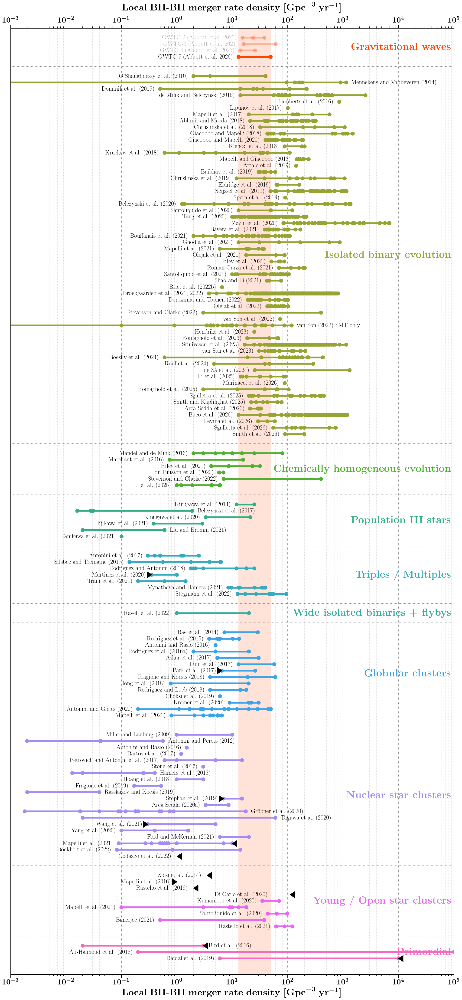

In [7]:
CHANNELS_BHBH = [
    "observations-GWs",
    "isolated-binary-evolution",
    "CHE",
    "population-III",
    "triples",
    "flybys",
    "globular-clusters",
    "nuclear-clusters",
    "young-stellar-clusters",
    "primordial",
]

fig_bhbh, ax_bhbh = make_figure(
    dco_type="BH-BH",
    channels=CHANNELS_BHBH,
    order="year",
    include_superseded=True,   # show GWTC-3 + GWTC-5; set False to hide old GW rates
    dim_superseded=True,       # GWTC-3 drawn at 30% opacity
    save_path=FIGURES_DIR / "Rates_BHBH_yearsorted",
    highlight_below_gwtc5=False
)
plt.show()


## 8 — NS-BH figure

Saved ../figures/Rates_NSBH_yearsorted.png and ../figures/Rates_NSBH_yearsorted.pdf


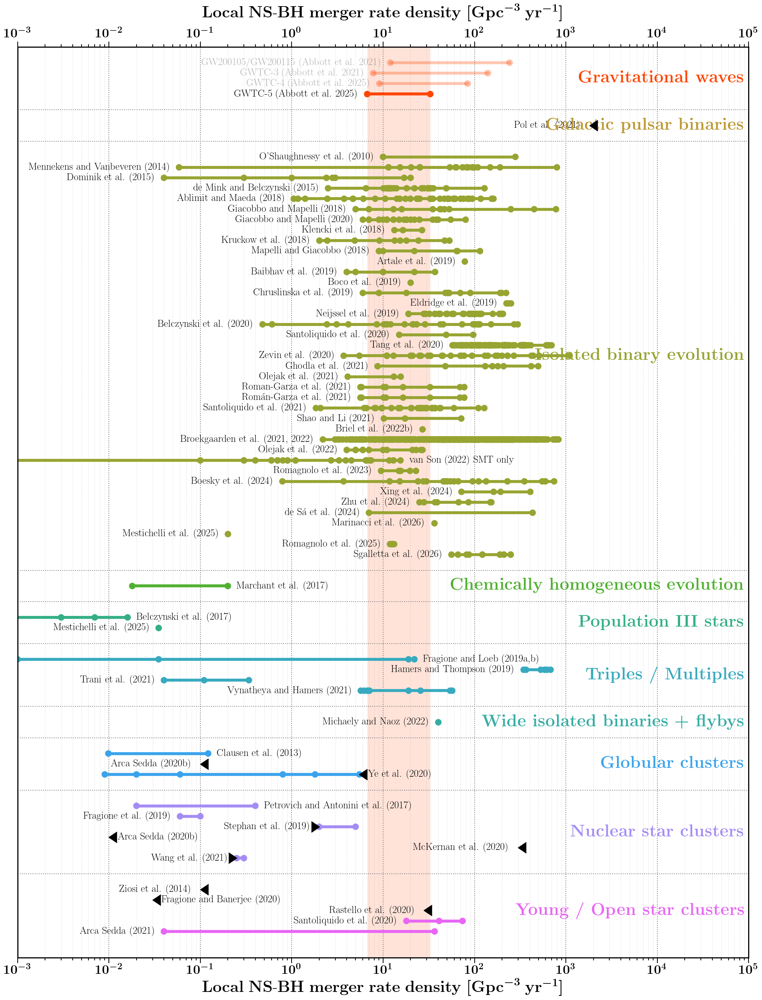

In [8]:
CHANNELS_NSBH = [
    "observations-GWs",
    "observations-pulsars",
    "isolated-binary-evolution",
    "CHE",
    "population-III",
    "triples",
    "flybys",
    "globular-clusters",
    "nuclear-clusters",
    "young-stellar-clusters",
]

fig_nsbh, ax_nsbh = make_figure(
    dco_type="NS-BH",
    channels=CHANNELS_NSBH,
    order="year",
    include_superseded=True,
    dim_superseded=True,
    save_path=FIGURES_DIR / "Rates_NSBH_yearsorted",
)
plt.show()


## 9 — NS-NS figure

Saved ../figures/Rates_NSNS_yearsorted.png and ../figures/Rates_NSNS_yearsorted.pdf


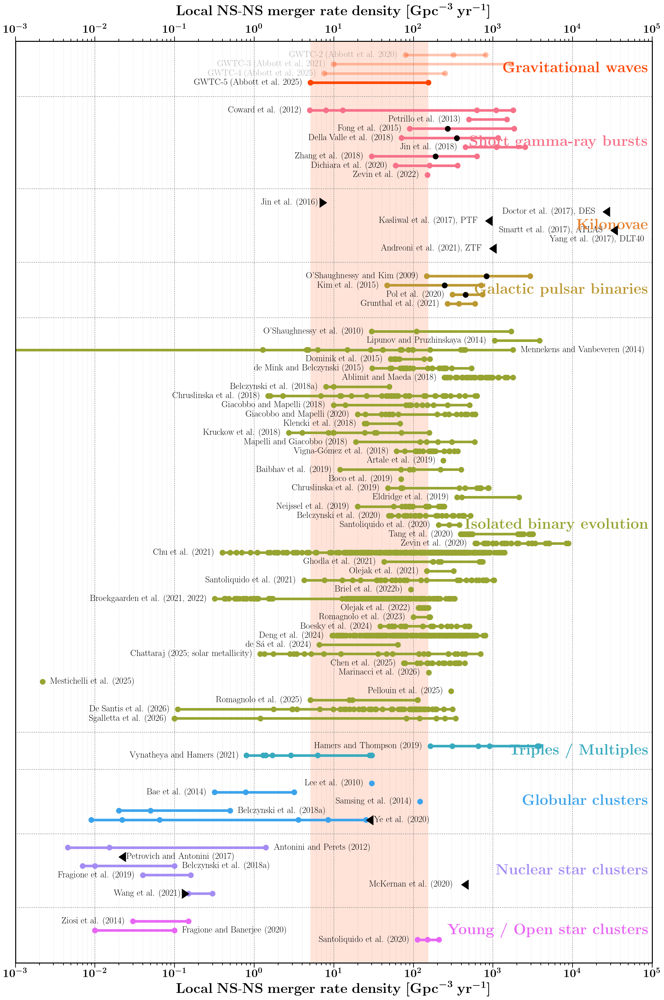

In [9]:
CHANNELS_NSNS = [
    "observations-GWs",
    "observations-sGRBs",
    "observations-kilonovae",
    "observations-pulsars",
    "isolated-binary-evolution",
    "triples",
    "globular-clusters",
    "nuclear-clusters",
    "young-stellar-clusters",
]

fig_nsns, ax_nsns = make_figure(
    dco_type="NS-NS",
    channels=CHANNELS_NSNS,
    order="year",
    include_superseded=True,
    dim_superseded=True,
    save_path=FIGURES_DIR / "Rates_NSNS_yearsorted",
)
plt.show()


# Focus on only isolated binary evolution  (For Lower your Rates) 

In [10]:
import pandas as pd

# --------------------------------------------------
# Load data
# --------------------------------------------------

df = pd.read_csv(
    DATA_DIR / "isolated-binary-evolution.csv",
    dtype=str,
).fillna("")

# --------------------------------------------------
# Standardize compact-object labels
# --------------------------------------------------

DCO_LABEL_MAP = {
    "BBH": "BBH",
    "BH-BH": "BBH",
    "BHBH": "BBH",

    "BHNS": "BHNS",
    "BH-NS": "BHNS",
    "NS-BH": "BHNS",
    "NSBH": "BHNS",

    "BNS": "BNS",
    "NS-NS": "BNS",
    "NSNS": "BNS",
}

df["DCO_type"] = (
    df["compact_object_type"]
    .str.upper()
    .str.strip()
    .map(DCO_LABEL_MAP)
)

# Keep only BBH, BHNS, and BNS entries
dco_df = df[df["DCO_type"].notna()].copy()

# Remove entries without a study identifier
dco_df = dco_df[dco_df["study_key"].str.strip().ne("")].copy()

# --------------------------------------------------
# Unique studies
# --------------------------------------------------

n_studies_total = dco_df["study_key"].nunique()

studies_per_dco = (
    dco_df.groupby("DCO_type")["study_key"]
    .nunique()
    .reindex(["BBH", "BHNS", "BNS"], fill_value=0)
)

# --------------------------------------------------
# Unique submodels
# --------------------------------------------------
# A submodel is defined by study_key + submodel.
#
# Including DCO_type in the total count means that a model reporting
# BBH, BHNS, and BNS rates contributes one submodel to each DCO sample.

submodels = (
    dco_df[["DCO_type", "study_key", "submodel"]]
    .drop_duplicates()
)

n_submodels_total = len(submodels)

submodels_per_dco = (
    submodels.groupby("DCO_type")
    .size()
    .reindex(["BBH", "BHNS", "BNS"], fill_value=0)
)

# --------------------------------------------------
# Print summary
# --------------------------------------------------

print("=" * 60)
print("ISOLATED BINARY EVOLUTION DATASET SUMMARY")
print("=" * 60)

print("\nUNIQUE STUDIES")
print("-" * 60)
print(f"All DCO types combined: {n_studies_total:>6}")

for dco_type in ["BBH", "BHNS", "BNS"]:
    print(
        f"{dco_type}:"
        f"{studies_per_dco[dco_type]:>{26 - len(dco_type)}}"
    )

print("\nUNIQUE SUBMODELS")
print("-" * 60)
print(f"All DCO samples combined: {n_submodels_total:>4}")

for dco_type in ["BBH", "BHNS", "BNS"]:
    print(
        f"{dco_type}:"
        f"{submodels_per_dco[dco_type]:>{26 - len(dco_type)}}"
    )

print("=" * 60)

ISOLATED BINARY EVOLUTION DATASET SUMMARY

UNIQUE STUDIES
------------------------------------------------------------
All DCO types combined:     72
BBH:                     57
BHNS:                    39
BNS:                     43

UNIQUE SUBMODELS
------------------------------------------------------------
All DCO samples combined: 4194
BBH:                   1490
BHNS:                  1007
BNS:                   1697


Saved ../figures/Rates_BHBH_yearsorted_isolated_only.png and ../figures/Rates_BHBH_yearsorted_isolated_only.pdf


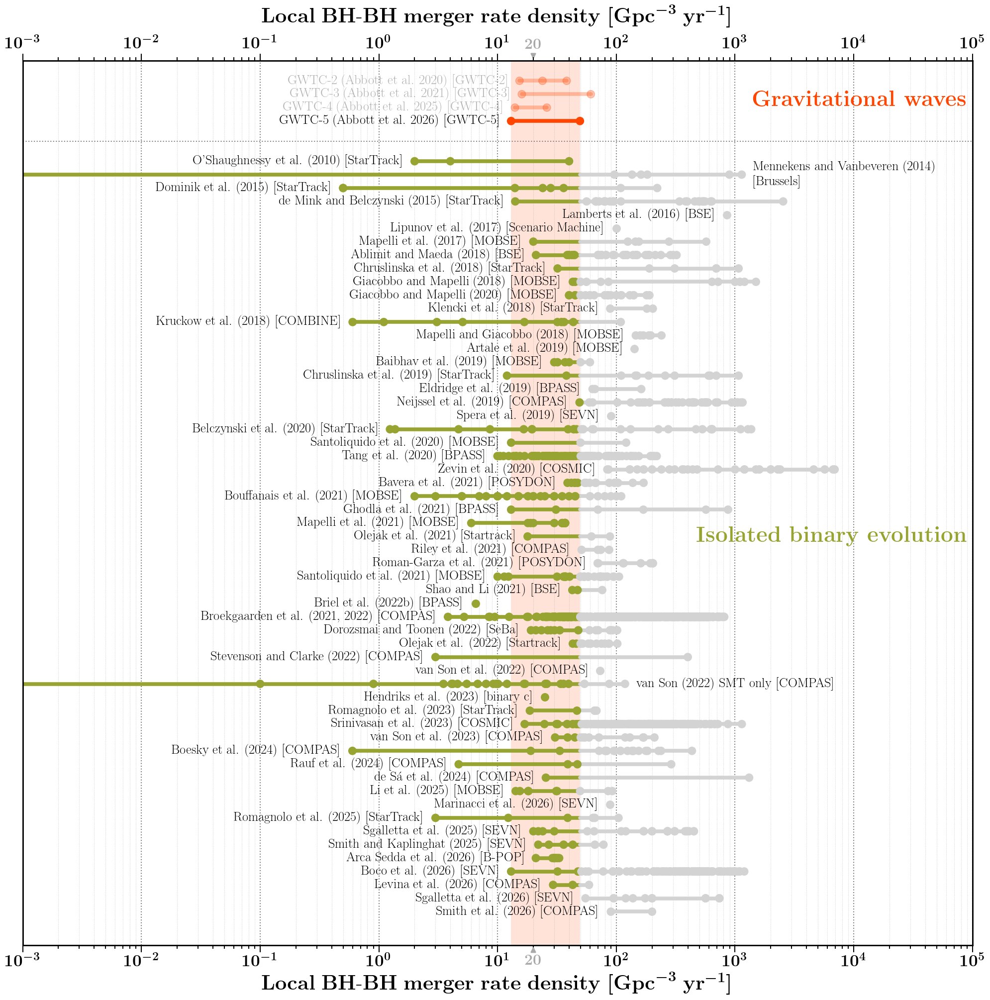

In [11]:
CHANNELS_BHBH = [
    "observations-GWs",
    "isolated-binary-evolution",
]

fig_bhbh, ax_bhbh = make_figure(
    dco_type="BH-BH",
    channels=CHANNELS_BHBH,
    order="year",
    include_superseded=True,   # show GWTC-3 + GWTC-5; set False to hide old GW rates
    dim_superseded=True,       # GWTC-3 drawn at 30% opacity
    save_path=FIGURES_DIR / "Rates_BHBH_yearsorted_isolated_only",
    highlight_below_gwtc5=True,
    highlight_channels=["isolated-binary-evolution"],
    code_label=True
)
plt.show()


Saved ../figures/Rates_BHNS_yearsorted_isolated_only.png and ../figures/Rates_BHNS_yearsorted_isolated_only.pdf


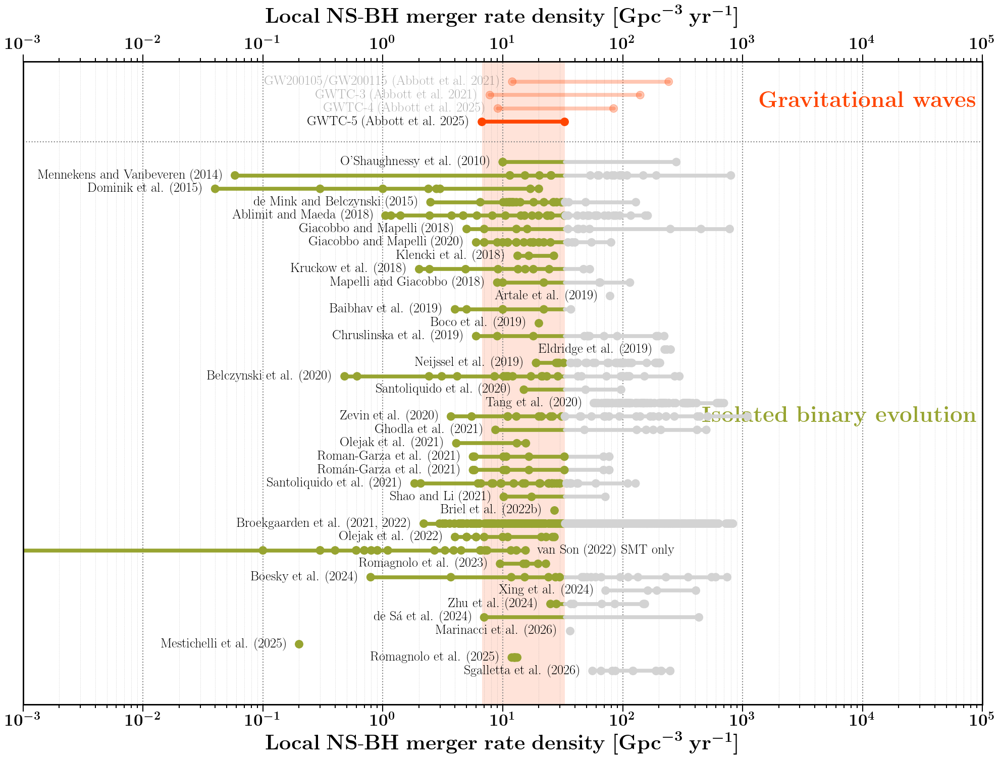

In [12]:
CHANNELS_BHNS = [
    "observations-GWs",
    "isolated-binary-evolution",
]

fig_bhbh, ax_bhbh = make_figure(
    dco_type="NS-BH",
    channels=CHANNELS_BHNS,
    order="year",
    include_superseded=True,   # show GWTC-3 + GWTC-5; set False to hide old GW rates
    dim_superseded=True,       # GWTC-3 drawn at 30% opacity
    save_path=FIGURES_DIR / "Rates_BHNS_yearsorted_isolated_only",
    highlight_below_gwtc5=True,
    highlight_channels=["isolated-binary-evolution"],
)
plt.show()


Saved ../figures/Rates_NSNS_yearsorted_isolated_only.png and ../figures/Rates_NSNS_yearsorted_isolated_only.pdf


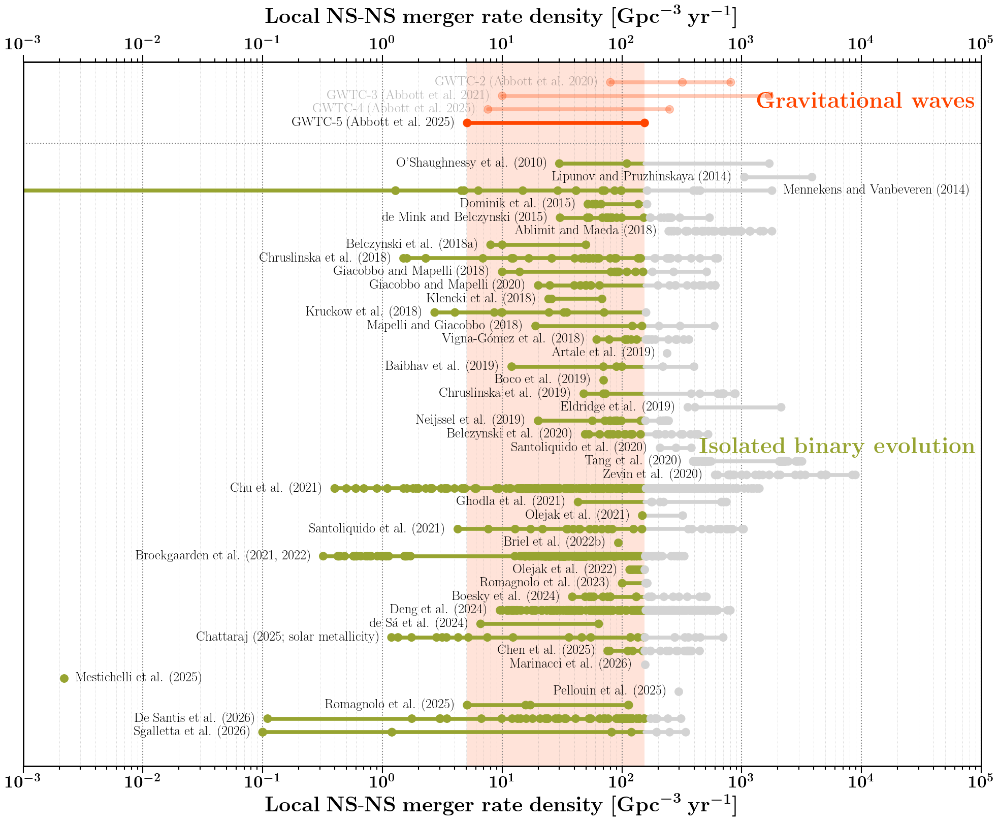

In [13]:
CHANNELS_NSNS = [
    "observations-GWs",
    "isolated-binary-evolution",
]

fig_bhbh, ax_bhbh = make_figure(
    dco_type="NS-NS",
    channels=CHANNELS_NSNS,
    order="year",
    include_superseded=True,   # show GWTC-3 + GWTC-5; set False to hide old GW rates
    dim_superseded=True,       # GWTC-3 drawn at 30% opacity
    save_path=FIGURES_DIR / "Rates_NSNS_yearsorted_isolated_only",
    highlight_below_gwtc5=True,
    highlight_channels=["isolated-binary-evolution"],
)
plt.show()


# Map parameter assumptions, code etc. 

In [14]:
import pandas as pd
import numpy as np

# --------------------------------------------------
# Observational limits
# --------------------------------------------------

LVK_LOW  = 27.5
LVK_HIGH = 49.4

# --------------------------------------------------
# Load
# --------------------------------------------------

df = pd.read_csv(
    DATA_DIR / "isolated-binary-evolution.csv",
    dtype=str,
).fillna("")

# BBH only
bbh = df[
    df["compact_object_type"]
    .str.upper()
    .isin(["BH-BH", "BBH"])
].copy()

bbh["rate"] = pd.to_numeric(bbh["rate_Gpc3yr"], errors="coerce")
bbh = bbh[np.isfinite(bbh["rate"])]

# --------------------------------------------------
# Basic counts
# --------------------------------------------------

n_studies = bbh["study_key"].nunique()

n_submodels = (
    bbh[["study_key", "submodel"]]
    .drop_duplicates()
    .shape[0]
)

# --------------------------------------------------
# Relative to LVK range
# --------------------------------------------------

below_lvk = (bbh["rate"] < LVK_LOW).sum()

within_lvk = (
    (bbh["rate"] >= LVK_LOW)
    & (bbh["rate"] <= LVK_HIGH)
).sum()

above_lvk = (bbh["rate"] > LVK_HIGH).sum()

# --------------------------------------------------
# Print
# --------------------------------------------------

print("=" * 60)
print("BBH LOCAL MERGER RATE SUMMARY")
print("=" * 60)

print(f"Number of studies:              {n_studies}")
print(f"Number of BBH submodels:        {n_submodels}")
print()

print(f"Below low LVK range (<{LVK_LOW}):      {below_lvk}")
print(f"Within LVK range:              {within_lvk}")
print(f"Below high LVK range (<{LVK_HIGH}):      {below_lvk}")
print(f"Above LVK range (>{LVK_HIGH}):     {above_lvk}")
print()

print(
    f"Fraction within LVK range: "
    f"{within_lvk/n_submodels:.1%}"
)


print(
    f"Fraction above LVK range: "
    f"{above_lvk/n_submodels:.1%}"
)

BBH LOCAL MERGER RATE SUMMARY
Number of studies:              57
Number of BBH submodels:        1490

Below low LVK range (<27.5):      160
Within LVK range:              198
Below high LVK range (<49.4):      160
Above LVK range (>49.4):     1220

Fraction within LVK range: 13.3%
Fraction above LVK range: 81.9%


In [15]:
study_summary = (
    bbh.groupby("study_key")["rate"]
    .agg(["min", "max"])
)

n_studies_with_lvk = (
    ((study_summary["min"] <= LVK_HIGH) &
     (study_summary["max"] >= LVK_LOW))
).sum()

print(
    f"Studies with at least one model "
    f"overlapping LVK range: "
    f"{n_studies_with_lvk}/{len(study_summary)}"
)

Studies with at least one model overlapping LVK range: 41/57


In [16]:
LVK_LOW  = 27.5
LVK_HIGH = 49.4

bbh = df[
    df["compact_object_type"].str.upper().isin(["BH-BH", "BBH"])
].copy()

bbh["rate"] = pd.to_numeric(bbh["rate_Gpc3yr"], errors="coerce")
bbh = bbh[np.isfinite(bbh["rate"]) & (bbh["rate"] > 0)].copy()

# Optional: only if your plot removes exact duplicate rows
# bbh = bbh.drop_duplicates(
#     subset=["study_key", "submodel", "rate_Gpc3yr", "formation_channel"]
# )

n_studies = bbh["study_key"].nunique()
n_points = len(bbh)

below_lvk = (bbh["rate"] < LVK_LOW).sum()
within_lvk = ((bbh["rate"] >= LVK_LOW) & (bbh["rate"] <= LVK_HIGH)).sum()
below_or_within_lvk = (bbh["rate"] <= LVK_HIGH).sum()
above_lvk = (bbh["rate"] > LVK_HIGH).sum()

print("=" * 60)
print("BBH LOCAL MERGER RATE SUMMARY")
print("=" * 60)
print(f"Number of studies:                     {n_studies}")
print(f"Number of BBH plotted points/rates:    {n_points}")
print()
print(f"Below LVK range (<{LVK_LOW}):             {below_lvk}")
print(f"Within LVK range ({LVK_LOW}-{LVK_HIGH}):       {within_lvk}")
print(f"Below or within LVK (≤{LVK_HIGH}):          {below_or_within_lvk}")
print(f"Above LVK range (>{LVK_HIGH}):            {above_lvk}")
print()
print(f"Fraction below or within LVK:           {below_or_within_lvk/n_points:.1%}")
print(f"Check total:                            {below_lvk + within_lvk + above_lvk}")


BBH LOCAL MERGER RATE SUMMARY
Number of studies:                     57
Number of BBH plotted points/rates:    1560

Below LVK range (<27.5):             142
Within LVK range (27.5-49.4):       198
Below or within LVK (≤49.4):          340
Above LVK range (>49.4):            1220

Fraction below or within LVK:           21.8%
Check total:                            1560


In [17]:
# ── Build clean BBH dataframe ───────────────────────────────────────────────

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

LVK_LOW  = 27.5
LVK_HIGH = 49.4
BOCO_R0  = 20.0

# If needed, rebuild bbh from your main dataframe `df`
bbh = df[
    df["compact_object_type"]
    .str.upper()
    .isin(["BH-BH", "BBH"])
].copy()

bbh["rate"] = pd.to_numeric(bbh["rate_Gpc3yr"], errors="coerce")
bbh = bbh[np.isfinite(bbh["rate"]) & (bbh["rate"] > 0)].copy()

bbh["code"] = (
    bbh["code"]
    .fillna("Unknown")
    .replace({"": "Unknown", "nan": "Unknown", "None": "Unknown"})
    .astype(str)
    .str.strip()
)

print(f"BBH rate points: {len(bbh)}")
print(f"Studies: {bbh['study_key'].nunique()}")
print(f"Codes: {bbh['code'].nunique()}")

BBH rate points: 1560
Studies: 57
Codes: 15


In [18]:
# ── Load data ────────────────────────────────────────────────────────────────
DATA_DIR = Path("../data")

# The relationships CSV drives this figure — BH-BH rates are embedded per submodel.
rels = pd.read_csv(DATA_DIR / "isolated-binary-evolution_relationships.csv")
rels["from_rate"] = pd.to_numeric(rels["from_rate_Gpc3yr"], errors="coerce")
rels["to_rate"]   = pd.to_numeric(rels["to_rate_Gpc3yr"],   errors="coerce")

# Pull publication year from the main CSV for within-panel sort order
_year_map = (
    pd.read_csv(DATA_DIR / "isolated-binary-evolution.csv", dtype=str).fillna("")
    .drop_duplicates("study_key")
    .set_index("study_key")["year"]
    .apply(pd.to_numeric, errors="coerce")
)
rels["year"] = rels["study_key"].map(_year_map)

print(f"Relationships loaded: {len(rels)} rows, {rels['study_key'].nunique()} studies")
print(f"Unique parameter families:    {sorted(rels['parameter_family'].unique())}")




# ── Load data ────────────────────────────────────────────────────────────────
DATA_DIR = Path("../data")

rels = pd.read_csv(DATA_DIR / "isolated-binary-evolution_relationships.csv")
rels["from_rate"] = pd.to_numeric(rels["from_rate_Gpc3yr"], errors="coerce")
rels["to_rate"]   = pd.to_numeric(rels["to_rate_Gpc3yr"],   errors="coerce")

_year_map = (
    pd.read_csv(DATA_DIR / "isolated-binary-evolution.csv", dtype=str).fillna("")
    .drop_duplicates("study_key")
    .set_index("study_key")["year"]
    .apply(pd.to_numeric, errors="coerce")
)
rels["year"] = rels["study_key"].map(_year_map)

# ── Use parameter_family directly as the panel ───────────────────────────────
# parameter_family already encodes the grouping; no manual mapping needed.
# Optionally apply a rename dict here if you want different display labels.
rels["panel"] = rels["parameter_family"].fillna("Other")



# Build a flat table: one row per unique (panel, study_key, submodel) point.
# Each relationship row contributes its two endpoints; duplicates are removed.
_from = rels[["study_key", "label", "year", "panel",
              "from_submodel", "from_rate", "compact_object_type"]].rename(
    columns={"from_submodel": "submodel", "from_rate": "rate"})
_to   = rels[["study_key", "label", "year", "panel",
              "to_submodel", "to_rate", "compact_object_type"]].rename(
    columns={"to_submodel": "submodel", "to_rate": "rate"})
pts = (pd.concat([_from, _to], ignore_index=True)
         .drop_duplicates(subset=["panel", "study_key", "submodel", "compact_object_type"])
         .copy())
pts["is_fiducial"] = (pts["submodel"].str.lower().str.contains("fiducial") |
                      (pts["submodel"] == "ref"))

# Build a flat table of edges: one row per relationship, carrying its panel.
# Each edge is drawn as its own line segment between its two submodels'
# rates, so a study with several disjoint "chains" (e.g. Boesky's alpha_CE
# sweep repeated at 3 fixed beta_MT values) shows 3 separate segments
# rather than one misleading min-to-max bar across all of them.
edges = (rels[["study_key", "panel", "from_submodel", "to_submodel",
               "from_rate", "to_rate"]]
           .dropna(subset=["from_rate", "to_rate"])
           .copy())

print(f"Total (panel, study, submodel) points: {len(pts)}")
print(f"Edges with both rates available:       {len(edges)}")
print(f"Panels (parameter family options in file): {sorted(pts['panel'].unique())}")
pts.head(8)

Relationships loaded: 7943 rows, 53 studies
Unique parameter families:    ['BH spin', 'CE optimistic/pessimistic', 'IMBH_seeds', 'angular momentum', 'binding energy lambda', 'circularisation', 'common envelope efficiency (alpha_CE)', 'convective envelope criteria', 'core mass fraction', 'core-envelope boundary (H-fraction)', 'delay-time distribution (DTD slope)', 'initial conditions', 'mass transfer', 'mass transfer efficiency', 'mass transfer stability', 'natal kick', 'other CE physics', 'population synthesis code', 'remnant mass prescription', 'star formation history', 'stellar tracks', 'stellar winds', 'tidal effects']
Total (panel, study, submodel) points: 7387
Edges with both rates available:       7943
Panels (parameter family options in file): ['BH spin', 'CE optimistic/pessimistic', 'IMBH_seeds', 'angular momentum', 'binding energy lambda', 'circularisation', 'common envelope efficiency (alpha_CE)', 'convective envelope criteria', 'core mass fraction', 'core-envelope boundary (

,study_key,label,year,panel,submodel,rate,compact_object_type,is_fiducial
0,Olejak_2021_Startrack,Olejak et al. (2021),2021,mass transfer stability,M380.B,61.7,BH-BH,False
1,Olejak_2021_Startrack,Olejak et al. (2021),2021,mass transfer stability,M480.B,88.4,BH-BH,False
2,Olejak_2021_Startrack,Olejak et al. (2021),2021,mass transfer stability,M380.B,13.1,NS-BH,False
3,Olejak_2021_Startrack,Olejak et al. (2021),2021,mass transfer stability,M480.B,15.6,NS-BH,False
4,Olejak_2021_Startrack,Olejak et al. (2021),2021,mass transfer stability,M380.B,148.0,NS-NS,False
5,Olejak_2021_Startrack,Olejak et al. (2021),2021,mass transfer stability,M480.B,148.0,NS-NS,False
6,Olejak_2022_Startrack,Olejak et al. (2022),2022,remnant mass prescription,1,50.0,BH-BH,False
7,Olejak_2022_Startrack,Olejak et al. (2022),2022,remnant mass prescription,2,43.0,BH-BH,False


In [19]:




# ── Build panel structure ────────────────────────────────────────────────────
PANEL_ORDER = [
    "common envelope efficiency (alpha_CE)",
    "CE optimistic/pessimistic",
    "mass transfer efficiency",
    "mass transfer stability",
    "natal kick",
    "remnant mass prescription",
    "stellar tracks",
    "star formation history",
    "initial conditions",
    "angular momentum",
    'stellar winds', 
    'binding energy lambda',
    'convective envelope criteria',
    'CE efficiency & binding energy (alpha & lambda)',
    'other CE physics',
    # add others as needed
]
#
#     'tidal effects',


PANEL_DISPLAY_NAMES = {
    "common envelope efficiency (alpha_CE)": r"CE efficiency ($\alpha_{\rm CE}$)",
    "CE optimistic/pessimistic":             r"CE pessimistic/optimistic",
    "mass transfer efficiency":              r"Mass transfer efficiency (e.g. $\beta$)",
    "mass transfer stability":               r"Mass transfer stability",
    "natal kick":                            r"Natal kicks (e.g. $\sigma_{\rm kick}$)",
    "remnant mass prescription":             r"Remnant mass prescription",
    "stellar tracks":                        r"Stellar evolution tracks",
    "star formation history":                r"Star formation history",
    "initial conditions":                    r"Initial conditions",
    "angular momentum":                      r"Angular momentum",
    'stellar winds':                         r"Stellar winds",
    'binding energy lambda':                 r"Binding energy $(\lambda)$",
    'convective envelope criteria':          r'convective envelope criteria',
    'CE efficiency & binding energy (alpha & lambda)': r"$\alpha \lambda$",
    'other CE physics':                      r'other CE physics',
#     'tidal effects':                         r'tides',
    # etc.
}
# Apply when labelling axes, not when grouping:



panels = {}
for panel_name in PANEL_ORDER:
    panel_pts = pts[pts["panel"] == panel_name]
    if panel_pts.empty:
        continue
    panel_edges = edges[edges["panel"] == panel_name]
    studies = (panel_pts.drop_duplicates("study_key")
                        .sort_values("year")["study_key"].tolist())
    panels[panel_name] = {"studies": studies, "pts": panel_pts, "edges": panel_edges}



print("Panels and studies:")
for g, p in panels.items():
    print(f"  [{g}]:")
    for sk in p["studies"]:
        n_sub = p["pts"][p["pts"]["study_key"] == sk]["submodel"].nunique()
        n_edg = (p["edges"]["study_key"] == sk).sum()
        print(f"    {sk}  ({n_sub} submodels, {n_edg} edges)")
        
        
print("\n")
print("\n")

mapped = set(PANEL_DISPLAY_NAMES.keys())
all_families = set(rels["parameter_family"].dropna().unique())
unmapped = sorted(all_families - mapped)

print(f"{len(unmapped)} unmapped parameter families:")

for family in unmapped:
    family_rows = rels[rels["parameter_family"] == family]

    n_studies = family_rows["study_key"].nunique()
    n_rows = len(family_rows)

    print(
        f"  {family!r}: "
        f"{n_studies} studies, "
        f"{n_rows} entries"
    )

print("\n")




Panels and studies:
  [common envelope efficiency (alpha_CE)]:
    Mennekens_2014_Brusselscode  (6 submodels, 8 edges)
    Mapelli_2017_MOBSE  (3 submodels, 2 edges)
    Ablimit_2018_BSE  (2 submodels, 9 edges)
    VignaGmez_2018_COMPAS  (3 submodels, 2 edges)
    Mapelli_2018_MOBSE  (6 submodels, 12 edges)
    Giacobbo_2018_MOBSE  (12 submodels, 24 edges)
    Baibhav_2019_MOBSE  (6 submodels, 12 edges)
    Zevin_2020_COSMIC  (32 submodels, 48 edges)
    Santoliquido_2021_MOBSE  (7 submodels, 18 edges)
    Bouffanais_2021_MOBSE  (30 submodels, 20 edges)
    Bavera_2021_POSYDON  (7 submodels, 6 edges)
    Mapelli_2021_MOBSE  (9 submodels, 6 edges)
    Chu_2021_BSE  (108 submodels, 72 edges)
    Broekgaarden_COMPAS  (5 submodels, 12 edges)
    Srinivasan_2023_COSMIC  (54 submodels, 48 edges)
    Boesky_2024_COMPAS  (12 submodels, 27 edges)
    Xing_2024_POSYDON  (2 submodels, 1 edges)
    Deng_2024_BSE  (324 submodels, 270 edges)
    Zhu_2024_COMPAS  (8 submodels, 6 edges)
    Sgalletta_

9 unmapped parameter families:
  'BH spin': 2 studies, 10 entries
  'IMBH_seeds': 1 studies, 1 entries
  'circularisation': 1 studies, 2 entries
  'core mass fraction': 1 studies, 8 entries
  'core-envelope boundary (H-fraction)': 1 studies, 1 entries
  'delay-time distribution (DTD slope)': 1 studies, 4 entries
  'mass transfer': 1 studies, 10 entries
  'population synthesis code': 1 studies, 1 entries
  'tidal effects': 2 studies, 10 entries




In [20]:
# Keep rows with both rates known
df = rels.copy()
df["from_rate_Gpc3yr"] = pd.to_numeric(df["from_rate_Gpc3yr"], errors="coerce")
df["to_rate_Gpc3yr"] = pd.to_numeric(df["to_rate_Gpc3yr"], errors="coerce")
df = df.dropna(subset=["from_rate_Gpc3yr", "to_rate_Gpc3yr"])
LIMIT = 49.4
successful = df[
    (df["from_rate_Gpc3yr"] > LIMIT) &
    (df["to_rate_Gpc3yr"] < LIMIT)
].copy()
successful["rate_reduction_factor"] = (
    successful["from_rate_Gpc3yr"] /
    successful["to_rate_Gpc3yr"]
)
successful = successful.sort_values(
    "rate_reduction_factor",
    ascending=False
)
display(
    successful[
        [
            "label",
            "parameter_family",
            "parameter",
            "travel_label",
            "from_value", 
            "to_value",
            "from_rate_Gpc3yr",
            "to_rate_Gpc3yr",
            "rate_reduction_factor",
        ]
    ]
)

,label,parameter_family,parameter,travel_label,from_value,to_value,from_rate_Gpc3yr,to_rate_Gpc3yr,rate_reduction_factor
7876,Mennekens and Vanbeveren (2014),common envelope efficiency (alpha_CE),alpha_CE,model 2 to 8 (0.5 to 0.1),0.5,0.1,98.631000,0.000000,inf
1809,Chu et al. (2021),natal kick,sigma,Chu_α10_kl_β0.6_Millennium-II to Chu_α10_kh_β0...,kl,kh,688.000000,0.600000,1146.666667
2087,Chu et al. (2021),star formation history,SFRD_model,Chu_α0.1_kl_β0.6_Millennium-II to Chu_α0.1_kl_...,Millennium-II,EAGLE,255.000000,0.400000,637.500000
2119,Chu et al. (2021),star formation history,SFRD_model,Chu_α1.0_kh_β0.9_Illustris-TNG to Chu_α1.0_kh_...,Illustris-TNG,Madau_Dickinson,303.000000,0.500000,606.000000
3559,Ablimit and Maeda (2018),binding energy lambda,lambda,Ablimit_mod2_case2 to Ablimit_mod2_case8,NaN,NaN,676.260000,1.170000,578.000000
...,...,...,...,...,...,...,...,...,...
7173,"Broekgaarden et al. (2021, 2022)",star formation history,GSMF,N-SFRD122 to N-SFRD132,Furlong2015-single,Furlong2015-double,49.480252,49.128277,1.007164
7194,"Broekgaarden et al. (2021, 2022)",star formation history,GSMF,N-SFRD222 to N-SFRD232,Furlong2015-single,Furlong2015-double,49.534573,49.244174,1.005897
7176,"Broekgaarden et al. (2021, 2022)",star formation history,GSMF,N-SFRD123 to N-SFRD133,Furlong2015-single,Furlong2015-double,49.578380,49.374160,1.004136
7241,"Broekgaarden et al. (2021, 2022)",star formation history,MZR,O-SFRD212 to O-SFRD213,LangerNorman2006+offset,Ma2016,49.488068,49.294088,1.003935


In [21]:
import json

rows = (
    successful[["label", "parameter_family", "parameter", "travel_label",
                 "from_value", "to_value", "from_rate_Gpc3yr", "to_rate_Gpc3yr"]]
    .rename(columns={"from_rate_Gpc3yr": "from_rate", "to_rate_Gpc3yr": "to_rate"})
    .to_dict(orient="records")
)
print(json.dumps(rows, indent=2))

[
  {
    "label": "Mennekens and Vanbeveren (2014)",
    "parameter_family": "common envelope efficiency (alpha_CE)",
    "parameter": "alpha_CE",
    "travel_label": "model 2 to 8 (0.5 to 0.1)",
    "from_value": "0.5",
    "to_value": "0.1",
    "from_rate": 98.631,
    "to_rate": 0.0
  },
  {
    "label": "Chu et al. (2021)",
    "parameter_family": "natal kick",
    "parameter": "sigma",
    "travel_label": "Chu_\u03b110_kl_\u03b20.6_Millennium-II to Chu_\u03b110_kh_\u03b20.6_Millennium-II",
    "from_value": "kl",
    "to_value": "kh",
    "from_rate": 688.0,
    "to_rate": 0.6
  },
  {
    "label": "Chu et al. (2021)",
    "parameter_family": "star formation history",
    "parameter": "SFRD_model",
    "travel_label": "Chu_\u03b10.1_kl_\u03b20.6_Millennium-II to Chu_\u03b10.1_kl_\u03b20.6_EAGLE",
    "from_value": "Millennium-II",
    "to_value": "EAGLE",
    "from_rate": 255.0,
    "to_rate": 0.4
  },
  {
    "label": "Chu et al. (2021)",
    "parameter_family": "star formation

In [22]:
! ls ../

data
figures
lower-your-rates-supplementary_material.pdf
plotting_code
README.md


## by parameter

doing it for DCOtype BH-BH


/var/folders/07/v05tmc2s6p1f8qvmc216wrh80000gn/T/ipykernel_25726/3044973066.py:325: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


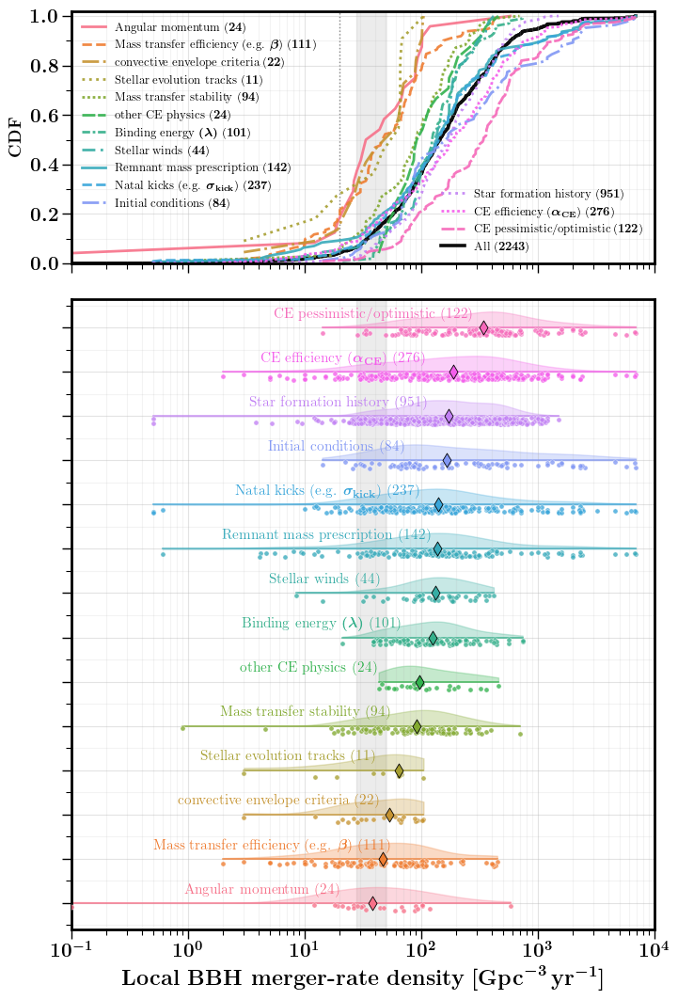

In [23]:
# ── CDF + log-space violin plot: BBH merger rates by parameter family ───────

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import LogLocator, MultipleLocator
from itertools import cycle
DCOtype="BH-BH"
xmin, xmax = -1, 4

# Build clean parameter-family dataframe
# param_df = pd.read_csv("../Data_Mandel_and_Broekgaarden_2026/isolated-binary-evolution_relationships.csv")
# param_df = pts.copy()


param_df = pts.copy()
param_df = pts[pts["compact_object_type"] == DCOtype].copy()
# param_df = param_df[param_df["compact_object_type"] == DCOtype].copy()
print('doing it for DCOtype', DCOtype)
param_df = param_df[
    np.isfinite(param_df["rate"]) &
    (param_df["rate"] > 0) &
    param_df["panel"].isin(PANEL_ORDER)
].copy()

param_df = param_df.drop_duplicates(
    subset=["panel", "study_key", "submodel", "rate"]
)





MIN_POINTS_PER_PANEL = 3

panel_counts = param_df["panel"].value_counts()
panels_to_plot = panel_counts[panel_counts >= MIN_POINTS_PER_PANEL].index.tolist()

# panel_order = [
#     p for p in PANEL_ORDER
#     if p in panels_to_plot
# ][::-1]

panel_order = [
    p for p in PANEL_ORDER
    if p in panels_to_plot
]

# Sort by median log10(rate)
panel_order = sorted(
    panel_order,
    key=lambda p: np.median(np.log10(param_df[param_df["panel"] == p]["rate"].values))
)

colors = sns.color_palette("husl", n_colors=len(panel_order))
panel_to_color = dict(zip(panel_order, colors))



linestyles = [
    "-",
    "--",
    "-.",
    ":",
    (0, (1, 1)),
    (0, (5, 1)),
    (0, (3, 1, 1, 1)),
    (0, (5, 2, 1, 2)),
]
linestyle_cycle = cycle(linestyles)
panel_to_linestyle = {panel: next(linestyle_cycle) for panel in panel_order}



fig_h = max(6.5, 0.72 * len(panel_order) + 2.6)

# Important: sharex=False because top panel is true log-axis,
# bottom panel is linear in log10(rate).
fig, (ax_cdf, ax) = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(8.0, fig_h),
    sharex=False,
    gridspec_kw={"height_ratios": [1.0, 2.5], "hspace": 0.08},
)

rng = np.random.default_rng(42)

# ── Top panel: CDFs in raw rate space, shown on log x-axis ──────────────────

for panel in panel_order:
    sub = param_df[param_df["panel"] == panel].copy()
    rates = np.sort(sub["rate"].values)
    cdf = np.arange(1, len(rates) + 1) / len(rates)
    
#     PANEL_DISPLAY_NAMES.get(panel_name, panel_name)

    ax_cdf.plot(
        rates,
        cdf,
        lw=2.0,
        color=panel_to_color[panel],
        linestyle=panel_to_linestyle[panel],
        alpha=0.9,
        label=rf"{PANEL_DISPLAY_NAMES.get(panel, panel)} (${len(rates)}$)",
    )
    
    
# ── Top panel: CDFs in raw rate space, shown on log x-axis ──────────────────

# All-codes combined CDF
all_rates = np.sort(param_df["rate"].values)
all_cdf = np.arange(1, len(all_rates) + 1) / len(all_rates)
ax_cdf.plot(
    all_rates,
    all_cdf,
    lw=2.6,
    color="black",
    alpha=0.95,
    zorder=1,
    label=rf"All (${len(all_rates)}$)",
)

ax_cdf.axvspan(LVK_LOW, LVK_HIGH, color="0.5", alpha=0.15, zorder=0)
ax_cdf.axvline(BOCO_R0, color="0.5", ls=":", lw=1, zorder=1)

ax_cdf.set_xscale("log")
ax_cdf.set_xlim(10**xmin, 10**xmax)

ax_cdf.xaxis.set_major_locator(LogLocator(base=10))
ax_cdf.xaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10)))

ax_cdf.set_ylim(0, 1.02)
ax_cdf.set_ylabel(r"\textbf{CDF}", fontsize=13)

ax_cdf.yaxis.set_major_locator(MultipleLocator(0.2))
ax_cdf.yaxis.set_minor_locator(MultipleLocator(0.1))

# Hide top x tick labels to reduce clutter
ax_cdf.tick_params(labelbottom=False)




handles, labels = ax_cdf.get_legend_handles_labels()

mid = (len(handles) // 2) +4

handles1 = handles[:mid]
labels1  = labels[:mid]

handles2 = handles[mid:]
labels2  = labels[mid:]

leg1 = ax_cdf.legend(
    handles1,
    labels1,
    loc="upper left",
    frameon=False,
    fontsize=9,
)

leg2 = ax_cdf.legend(
    handles2,
    labels2,
    loc="lower right",
    frameon=False,
    fontsize=9,
)

ax_cdf.add_artist(leg1)




# ── Bottom panel: violins in log10(rate) space ──────────────────────────────

for i, panel in enumerate(panel_order):
    sub = param_df[param_df["panel"] == panel].copy()
    rates = sub["rate"].values

    # KDE/violin is computed in log-rate space
    x = np.log10(rates)

    color = panel_to_color[panel]

    if len(x) >= 3:
        parts = ax.violinplot(
            [x],
            positions=[i],
            vert=False,
            widths=0.72,
            showmeans=False,
            showmedians=False,
            showextrema=False,
        )

        for body in parts["bodies"]:
            body.set_facecolor(color)
            body.set_edgecolor(color)
            body.set_alpha(0.28)
            body.set_zorder(1)

            # Half violin: keep only upper half
            path = body.get_paths()[0]
            vertices = path.vertices
            vertices[:, 1] = np.maximum(vertices[:, 1], i)

    jitter = rng.uniform(-0.18, -0.04, len(x))

    ax.scatter(
        x,
        i + jitter,
        s=14,
        alpha=0.78,
        color=color,
        edgecolor="white",
        linewidth=0.35,
        zorder=3,
    )

    # Median marker in log-rate space
    median_x = np.median(x)
    ax.scatter(
        median_x,
        i,
        marker="d",
        s=58,
        facecolor=color,
        edgecolor="black",
        linewidth=0.6,
        zorder=4,
    )

    # Min-max whisker in log-rate space
    ax.plot(
        [np.min(x), np.max(x)],
        [i, i],
        lw=1.2,
        color=color,
        alpha=0.75,
        zorder=2,
    )

    # Parameter-family label next to violin
    label_x = median_x - 0.95

    ax.text(
        label_x,
        i + 0.3,
        f"{PANEL_DISPLAY_NAMES.get(panel, panel)} ({len(x)})",
        color=color,
        fontsize=11,
        fontweight="bold",
        va="center",
        ha="center",
    )

# Observational comparison region in log10-rate space
ax.axvspan(
    np.log10(LVK_LOW),
    np.log10(LVK_HIGH),
    color="0.5",
    alpha=0.15,
    zorder=0,
)

# ax.axvline(
#     np.log10(BOCO_R0),
#     color="0.5",
#     ls=":",
#     lw=1,
#     zorder=1,
# )

ax.set_yticks(np.arange(len(panel_order)))
ax.set_yticklabels([""] * len(panel_order))
ax.set_ylim(-0.6, len(panel_order) - 0.35)

# Bottom x-axis: linear in log10(rate), labeled as rate
ax.set_xlim(xmin, xmax)

major_ticks = np.arange(xmin, xmax + 1)
ax.set_xticks(major_ticks)
ax.set_xticklabels([rf"$10^{{{int(t)}}}$" for t in major_ticks])

# Bottom x-axis: linear in log10(rate), labeled as rate
ax.set_xlim(xmin, xmax)

major_ticks = np.arange(xmin, xmax + 1)
ax.set_xticks(major_ticks)
ax.set_xticklabels([rf"$10^{{{int(t)}}}$" for t in major_ticks])

minor_ticks = []
for decade in range(xmin, xmax):
    minor_ticks.extend(decade + np.log10(np.arange(2, 10)))
ax.set_xticks(minor_ticks, minor=True)

ax.set_xlabel(
    r"$\textbf{Local BBH merger-rate density}$ "
    r"$[\mathrm{Gpc}^{-3}\,\mathrm{yr}^{-1}]$",
    fontsize=17,
)

ax.yaxis.set_minor_locator(MultipleLocator(0.5))

# ── Grid and tick styling ───────────────────────────────────────────────────

# for axis in (ax_cdf, ax):
#     axis.tick_params(
#         axis="both",
#         which="major",
        
#     )


for axis in (ax_cdf, ax):
    axis.grid(which="major", axis="both", alpha=0.35)
    axis.grid(which="minor", axis="both", alpha=0.15)

    axis.tick_params(axis="both", which="major", length=7, width=1.0, labelsize=15)
    axis.tick_params(axis="both", which="minor", length=4.5, width=0.8)


plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "BBH_rate_CDF_and_violin_by_parameter_family.pdf",
    bbox_inches="tight",
)

plt.savefig(
    FIGURES_DIR / "BBH_rate_CDF_and_violin_by_parameter_family.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

### by code

/var/folders/07/v05tmc2s6p1f8qvmc216wrh80000gn/T/ipykernel_25726/2872827592.py:304: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


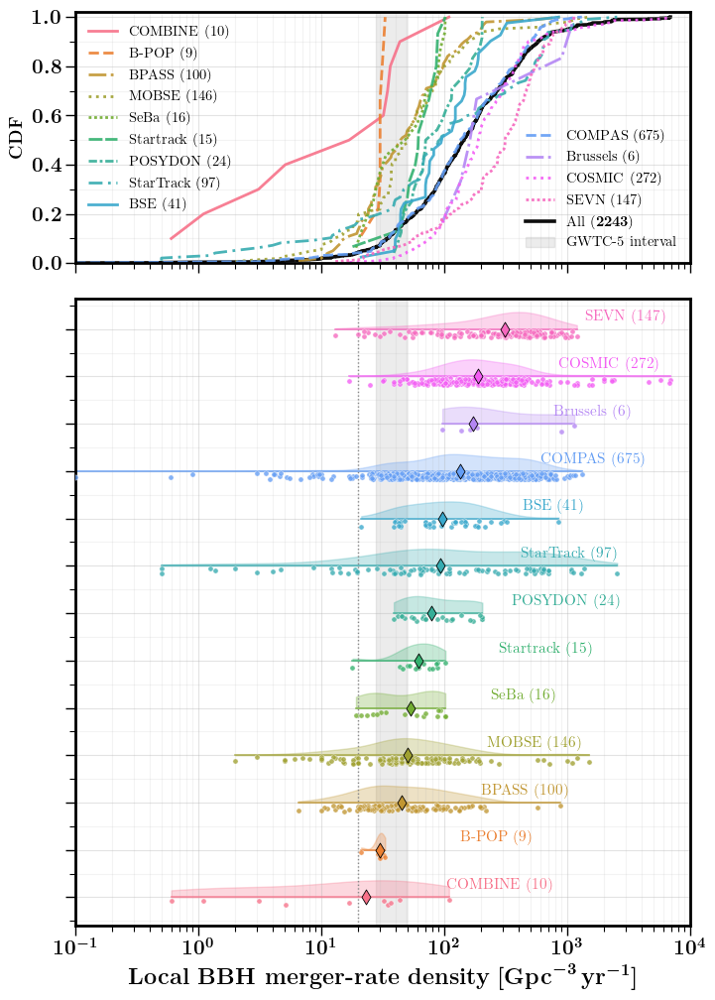

In [24]:
# ── CDF + log-space violin plot: BBH merger rates by population-synthesis code ──


xmin, xmax = -1, 4 # axes limits
# Build clean code dataframe
code_df = bbh.copy()

code_df = code_df[
    np.isfinite(code_df["rate"]) &
    (code_df["rate"] > 0)
].copy()

code_df["code"] = (
    code_df["code"]
    .fillna("Unknown")
    .replace({"": "Unknown", "nan": "Unknown"})
    .astype(str)
    .str.strip()
)

MIN_POINTS_PER_CODE = 5

code_counts = code_df["code"].value_counts()
codes_to_plot = code_counts[code_counts >= MIN_POINTS_PER_CODE].index.tolist()

# Sort codes by median BBH merger rate
code_order = (
    code_df[code_df["code"].isin(codes_to_plot)]
    .groupby("code")["rate"]
    .median()
    .sort_values()
    .index
    .tolist()
)

colors = sns.color_palette("husl", n_colors=len(code_order))
code_to_color = dict(zip(code_order, colors))

linestyles = [
    "-",
    "--",
    "-.",
    ":",
    (0, (1, 1)),
    (0, (5, 1)),
    (0, (3, 1, 1, 1)),
    (0, (5, 2, 1, 2)),
]
linestyle_cycle = cycle(linestyles)
code_to_linestyle = {code: next(linestyle_cycle) for code in code_order}

fig_h = max(6.5, 0.72 * len(code_order) + 2.6)

# Important: sharex=False because top panel is true log-axis,
# bottom panel is linear in log10(rate).
fig, (ax_cdf, ax) = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(8.0, fig_h),
    sharex=False,
    gridspec_kw={"height_ratios": [1.0, 2.5], "hspace": 0.08},
)

rng = np.random.default_rng(42)

# ── Top panel: CDFs in raw rate space, shown on log x-axis ──────────────────

for code in code_order:
    sub = code_df[code_df["code"] == code].copy()
    rates = np.sort(sub["rate"].values)
    cdf = np.arange(1, len(rates) + 1) / len(rates)

    ax_cdf.plot(
        rates,
        cdf,
        lw=2.0,
        color=code_to_color[code],
        linestyle=code_to_linestyle[code],
        alpha=0.9,
        label=f"{code} ({len(rates)})",
    )
    
    

# ── Top panel: CDFs in raw rate space, shown on log x-axis ──────────────────

# All-codes combined CDF
all_rates = np.sort(param_df["rate"].values)
all_cdf = np.arange(1, len(all_rates) + 1) / len(all_rates)
ax_cdf.plot(
    all_rates,
    all_cdf,
    lw=2.6,
    color="black",
    alpha=0.95,
    zorder=1,
    label=rf"All (${len(all_rates)}$)",
)


ax_cdf.axvspan(
    LVK_LOW,
    LVK_HIGH,
    color="0.5",
    alpha=0.15,
    zorder=0,
    label="GWTC-5 interval",
)

# ax_cdf.axvline(
#     BOCO_R0,
#     color="0.5",
#     ls=":",
#     lw=1,
#     zorder=1,
# )

ax_cdf.set_xscale("log")
ax_cdf.set_xlim(10**xmin, 10**xmax)

ax_cdf.xaxis.set_major_locator(LogLocator(base=10))
ax_cdf.xaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10)))

ax_cdf.set_ylim(0, 1.02)
ax_cdf.set_ylabel(r"\textbf{CDF}", fontsize=13)

ax_cdf.yaxis.set_major_locator(MultipleLocator(0.2))
ax_cdf.yaxis.set_minor_locator(MultipleLocator(0.1))

# Hide top x tick labels to reduce clutter
ax_cdf.tick_params(labelbottom=False)

# Split legend into two frameless legends
handles, labels = ax_cdf.get_legend_handles_labels()

mid = (len(handles) // 2) + 2

handles1 = handles[:mid]
labels1 = labels[:mid]

handles2 = handles[mid:]
labels2 = labels[mid:]

leg1 = ax_cdf.legend(
    handles1,
    labels1,
    loc="upper left",
    frameon=False,
    fontsize=10.5,
)

leg2 = ax_cdf.legend(
    handles2,
    labels2,
    loc="lower right",
    frameon=False,
    fontsize=10.5,
)

ax_cdf.add_artist(leg1)


# ── Bottom panel: violins in log10(rate) space ──────────────────────────────

for i, code in enumerate(code_order):
    sub = code_df[code_df["code"] == code].copy()
    rates = sub["rate"].values

    # KDE/violin is computed in log-rate space
    x = np.log10(rates)

    color = code_to_color[code]

    if len(x) >= 3:
        parts = ax.violinplot(
            [x],
            positions=[i],
            vert=False,
            widths=0.72,
            showmeans=False,
            showmedians=False,
            showextrema=False,
        )

        for body in parts["bodies"]:
            body.set_facecolor(color)
            body.set_edgecolor(color)
            body.set_alpha(0.28)
            body.set_zorder(1)

            # Half violin: keep only upper half
            path = body.get_paths()[0]
            vertices = path.vertices
            vertices[:, 1] = np.maximum(vertices[:, 1], i)

    jitter = rng.uniform(-0.18, -0.04, len(x))

    ax.scatter(
        x,
        i + jitter,
        s=14,
        alpha=0.78,
        color=color,
        edgecolor="white",
        linewidth=0.35,
        zorder=3,
    )

    # Median marker in log-rate space
    median_x = np.median(x)
    ax.scatter(
        median_x,
        i,
        marker="d",
        s=58,
        facecolor=color,
        edgecolor="black",
        linewidth=0.6,
        zorder=4,
    )

    # Min-max whisker in log-rate space
    ax.plot(
        [np.min(x), np.max(x)],
        [i, i],
        lw=1.2,
        color=color,
        alpha=0.75,
        zorder=2,
    )

    # Code label next to violin
    label_x = median_x + 0.65

    ax.text(
        label_x,
        i + 0.25,
        f"{code} ({len(x)})",
        color=color,
        fontsize=11,
        fontweight="bold",
        va="center",
        ha="left",
    )

# Observational comparison region in log10-rate space
ax.axvspan(
    np.log10(LVK_LOW),
    np.log10(LVK_HIGH),
    color="0.5",
    alpha=0.15,
    zorder=0,
)

ax.axvline(
    np.log10(BOCO_R0),
    color="0.5",
    ls=":",
    lw=1,
    zorder=1,
)

ax.set_yticks(np.arange(len(code_order)))
ax.set_yticklabels([""] * len(code_order))
ax.set_ylim(-0.6, len(code_order) - 0.35)

# Bottom x-axis: linear in log10(rate), labeled as rate
ax.set_xlim(xmin, xmax)

major_ticks = np.arange(xmin, xmax + 1)
ax.set_xticks(major_ticks)
ax.set_xticklabels([rf"$10^{{{int(t)}}}$" for t in major_ticks])

minor_ticks = []
for decade in range(xmin, xmax):
    minor_ticks.extend(decade + np.log10(np.arange(2, 10)))
ax.set_xticks(minor_ticks, minor=True)

ax.set_xlabel(
    r"$\textbf{Local BBH merger-rate density}$ "
    r"$[\mathrm{Gpc}^{-3}\,\mathrm{yr}^{-1}]$",
    fontsize=17,
)

ax.yaxis.set_minor_locator(MultipleLocator(0.5))

# ── Grid and tick styling ───────────────────────────────────────────────────

# for axis in (ax_cdf, ax):
#     axis.tick_params(
#         axis="both",
#         which="major",
        
#     )


for axis in (ax_cdf, ax):
    axis.grid(which="major", axis="both", alpha=0.35)
    axis.grid(which="minor", axis="both", alpha=0.15)

    axis.tick_params(axis="both", which="major", length=7, width=1.0, labelsize=15)
    axis.tick_params(axis="both", which="minor", length=4.5, width=0.8)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR /  "BBH_rate_CDF_and_violin_by_population_synthesis_code.pdf",
    bbox_inches="tight",
)

plt.savefig(
    FIGURES_DIR /  "BBH_rate_CDF_and_violin_by_population_synthesis_code.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## Make big interactive table

In [25]:
from merger_rate_table import make_merger_rate_table



rels    = pd.read_csv("../data/isolated-binary-evolution_relationships.csv")
studies = pd.read_csv("../data/isolated-binary-evolution.csv")

make_merger_rate_table(rels, studies_df=studies,
                       title        = "Lower your Rates: Isolated Binary Evolution Merger Rates Model Relationships",
                      output_file  = "../figures/interactive/merger_rate_table.html")

# make_merger_rate_table(
#     rels,
#     title        = "Lower your Rates: Isolated Binary Evolution Merger Rates Model Relationships",
#     limit_boco   = 20.0,
#     output_file  = "../figures/merger_rate_table.html",   # optional save
# )

Saved to ../figures/interactive/merger_rate_table.html


Type ↕,Study / label ↕,Parameter family ↕,Parameter ↕,Change ↕,From rate ↕,To rate ↕,Change factor ↕


In [26]:
# ! ls 

# BHNS and BNS parameter investigation

In [27]:
from itertools import cycle

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import LogLocator, MultipleLocator


LVK_BANDS = {
    "BH-BH": (27.5, 49.4),
    "NS-BH": (8.0, 140.0),
    "NS-NS": (10.0, 1700.0),
}

DCO_LABELS = {
    "BH-BH": "BBH",
    "NS-BH": "BHNS",
    "NS-NS": "BNS",
}


def make_parameter_family_figure(
    DCOtype: str,
    pts: pd.DataFrame,
    PANEL_ORDER: list,
    PANEL_DISPLAY_NAMES: dict,
    FIGURES_DIR,
    xmin: float = -1,
    xmax: float = 4,
    min_points_per_panel: int = 10,
    boco_r0: float | None = None,
    save: bool = True,
    show: bool = True,
):
    """
    Make CDF + log-space violin plot of merger rates by parameter family
    for a given compact-object type.

    Parameters
    ----------
    DCOtype : str
        One of "BH-BH", "NS-BH", "NS-NS".
    pts : pd.DataFrame
        Dataframe containing rate data.
    PANEL_ORDER : list
        Ordered list of parameter-family panels.
    PANEL_DISPLAY_NAMES : dict
        Mapping from internal panel names to display names.
    FIGURES_DIR : Path-like
        Directory to save figures.
    xmin, xmax : float
        log10 x-axis limits for bottom panel; top panel uses 10**xmin to 10**xmax.
    min_points_per_panel : int
        Minimum number of points required to include a panel.
    boco_r0 : float or None
        Optional reference rate to draw as a vertical dotted line.
    save : bool
        Whether to save the figure.
    show : bool
        Whether to display the figure.

    Returns
    -------
    fig, (ax_cdf, ax), param_df
    """
    if DCOtype not in LVK_BANDS:
        raise ValueError(
            f"Unknown DCOtype {DCOtype!r}. "
            f"Choose from {list(LVK_BANDS.keys())}."
        )

    dco_label = DCO_LABELS[DCOtype]
    LVK_LOW, LVK_HIGH = LVK_BANDS[DCOtype]

    print(f"Doing it for DCOtype = {DCOtype} ({dco_label})")

    # --------------------------------------------------
    # Build clean dataframe
    # --------------------------------------------------
    param_df = pts[pts["compact_object_type"] == DCOtype].copy()

    param_df = param_df[
        np.isfinite(param_df["rate"]) &
        (param_df["rate"] > 0) &
        param_df["panel"].isin(PANEL_ORDER)
    ].copy()

    param_df = param_df.drop_duplicates(
        subset=["panel", "study_key", "submodel", "rate"]
    )

    if param_df.empty:
        raise ValueError(f"No valid rows found for DCOtype={DCOtype}")

    # --------------------------------------------------
    # Determine panels to plot
    # --------------------------------------------------
    panel_counts = param_df["panel"].value_counts()
    panels_to_plot = panel_counts[panel_counts >= min_points_per_panel].index.tolist()

    panel_order = [p for p in PANEL_ORDER if p in panels_to_plot]

    panel_order = sorted(
        panel_order,
        key=lambda p: np.median(
            np.log10(param_df.loc[param_df["panel"] == p, "rate"].values)
        )
    )

    if len(panel_order) == 0:
        raise ValueError(
            f"No panels have at least {min_points_per_panel} points for {DCOtype}"
        )

    # --------------------------------------------------
    # Style maps
    # --------------------------------------------------
    colors = sns.color_palette("husl", n_colors=len(panel_order))
    panel_to_color = dict(zip(panel_order, colors))

    linestyles = [
        "-",
        "--",
        "-.",
        ":",
        (0, (1, 1)),
        (0, (5, 1)),
        (0, (3, 1, 1, 1)),
        (0, (5, 2, 1, 2)),
    ]
    linestyle_cycle = cycle(linestyles)
    panel_to_linestyle = {panel: next(linestyle_cycle) for panel in panel_order}

    # --------------------------------------------------
    # Figure
    # --------------------------------------------------
    fig_h = max(6.5, 0.72 * len(panel_order) + 2.6)

    fig, (ax_cdf, ax) = plt.subplots(
        nrows=2,
        ncols=1,
        figsize=(8.0, fig_h),
        sharex=False,
        gridspec_kw={"height_ratios": [1.0, 2.5], "hspace": 0.08},
    )

    rng = np.random.default_rng(42)

    # --------------------------------------------------
    # Top panel: CDFs
    # --------------------------------------------------
    for panel in panel_order:
        sub = param_df[param_df["panel"] == panel].copy()
        rates = np.sort(sub["rate"].values)
        cdf = np.arange(1, len(rates) + 1) / len(rates)

        ax_cdf.plot(
            rates,
            cdf,
            lw=2.0,
            color=panel_to_color[panel],
            linestyle=panel_to_linestyle[panel],
            alpha=0.9,
            label=rf"{PANEL_DISPLAY_NAMES.get(panel, panel)} (${len(rates)}$)",
        )

    # All-data CDF
    all_rates = np.sort(param_df["rate"].values)
    all_cdf = np.arange(1, len(all_rates) + 1) / len(all_rates)

    ax_cdf.plot(
        all_rates,
        all_cdf,
        lw=2.6,
        color="black",
        alpha=0.95,
        zorder=1,
        label=rf"All (${len(all_rates)}$)",
    )

    ax_cdf.axvspan(LVK_LOW, LVK_HIGH, color="0.5", alpha=0.15, zorder=0)

    if boco_r0 is not None:
        ax_cdf.axvline(boco_r0, color="0.5", ls=":", lw=1, zorder=1)

    ax_cdf.set_xscale("log")
    ax_cdf.set_xlim(10**xmin, 10**xmax)
    ax_cdf.xaxis.set_major_locator(LogLocator(base=10))
    ax_cdf.xaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10)))
    ax_cdf.set_ylim(0, 1.02)
    ax_cdf.set_ylabel(r"\textbf{CDF}", fontsize=13)
    ax_cdf.yaxis.set_major_locator(MultipleLocator(0.2))
    ax_cdf.yaxis.set_minor_locator(MultipleLocator(0.1))
    ax_cdf.tick_params(labelbottom=False)

    
    ax_cdf.text(
        0.98,
        0.75,
        DCOtype,
        transform=ax_cdf.transAxes,
        ha="right",
        va="top",
        fontsize=15,
        fontweight="bold",
    )
    
    
    # Legend split into two blocks
    handles, labels = ax_cdf.get_legend_handles_labels()
    mid = (len(handles) // 2) + 4

    handles1 = handles[:mid]
    labels1 = labels[:mid]
    handles2 = handles[mid:]
    labels2 = labels[mid:]

    leg1 = ax_cdf.legend(
        handles1,
        labels1,
        loc="upper left",
        frameon=False,
        fontsize=9,
    )

    leg2 = ax_cdf.legend(
        handles2,
        labels2,
        loc="lower right",
        frameon=False,
        fontsize=9,
    )

    ax_cdf.add_artist(leg1)

    # --------------------------------------------------
    # Bottom panel: violins in log10(rate)
    # --------------------------------------------------
    for i, panel in enumerate(panel_order):
        sub = param_df[param_df["panel"] == panel].copy()
        rates = sub["rate"].values
        x = np.log10(rates)

        color = panel_to_color[panel]

        if len(x) >= 3:
            parts = ax.violinplot(
                [x],
                positions=[i],
                vert=False,
                widths=0.72,
                showmeans=False,
                showmedians=False,
                showextrema=False,
            )

            for body in parts["bodies"]:
                body.set_facecolor(color)
                body.set_edgecolor(color)
                body.set_alpha(0.28)
                body.set_zorder(1)

                # Half violin
                path = body.get_paths()[0]
                vertices = path.vertices
                vertices[:, 1] = np.maximum(vertices[:, 1], i)

        jitter = rng.uniform(-0.18, -0.04, len(x))

        ax.scatter(
            x,
            i + jitter,
            s=14,
            alpha=0.78,
            color=color,
            edgecolor="white",
            linewidth=0.35,
            zorder=3,
        )

        median_x = np.median(x)
        ax.scatter(
            median_x,
            i,
            marker="d",
            s=58,
            facecolor=color,
            edgecolor="black",
            linewidth=0.6,
            zorder=4,
        )

        ax.plot(
            [np.min(x), np.max(x)],
            [i, i],
            lw=1.2,
            color=color,
            alpha=0.75,
            zorder=2,
        )

        label_x = median_x - 0.95
        ax.text(
            label_x,
            i + 0.3,
            f"{PANEL_DISPLAY_NAMES.get(panel, panel)} ({len(x)})",
            color=color,
            fontsize=11,
            fontweight="bold",
            va="center",
            ha="center",
        )

    ax.axvspan(
        np.log10(LVK_LOW),
        np.log10(LVK_HIGH),
        color="0.5",
        alpha=0.15,
        zorder=0,
    )

    ax.set_yticks(np.arange(len(panel_order)))
    ax.set_yticklabels([""] * len(panel_order))
    ax.set_ylim(-0.6, len(panel_order) - 0.35)

    ax.set_xlim(xmin, xmax)

    major_ticks = np.arange(xmin, xmax + 1)
    ax.set_xticks(major_ticks)
    ax.set_xticklabels([rf"$10^{{{int(t)}}}$" for t in major_ticks])

    minor_ticks = []
    for decade in range(xmin, xmax):
        minor_ticks.extend(decade + np.log10(np.arange(2, 10)))
    ax.set_xticks(minor_ticks, minor=True)

    ax.set_xlabel(
        rf"$\textbf{{Local {dco_label} merger-rate density}}$ "
        r"$[\mathrm{Gpc}^{-3}\,\mathrm{yr}^{-1}]$",
        fontsize=17,
    )

    ax.yaxis.set_minor_locator(MultipleLocator(0.5))

    # --------------------------------------------------
    # Grid / ticks
    # --------------------------------------------------
    for axis in (ax_cdf, ax):
        axis.grid(which="major", axis="both", alpha=0.35)
        axis.grid(which="minor", axis="both", alpha=0.15)
        axis.tick_params(axis="both", which="major", length=7, width=1.0, labelsize=15)
        axis.tick_params(axis="both", which="minor", length=4.5, width=0.8)

    plt.tight_layout()

    if save:
        base = FIGURES_DIR / f"{dco_label}_rate_CDF_and_violin_by_parameter_family"
        plt.savefig(base.with_suffix(".pdf"), bbox_inches="tight")
        plt.savefig(base.with_suffix(".png"), dpi=300, bbox_inches="tight")
        print(f"Saved to {base.with_suffix('.pdf')} and {base.with_suffix('.png')}")

    if show:
        plt.show()
    else:
        plt.close(fig)

    return fig, (ax_cdf, ax), param_df







Doing it for DCOtype = BH-BH (BBH)


/var/folders/07/v05tmc2s6p1f8qvmc216wrh80000gn/T/ipykernel_25726/3599630201.py:354: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved to ../figures/BBH_rate_CDF_and_violin_by_parameter_family.pdf and ../figures/BBH_rate_CDF_and_violin_by_parameter_family.png


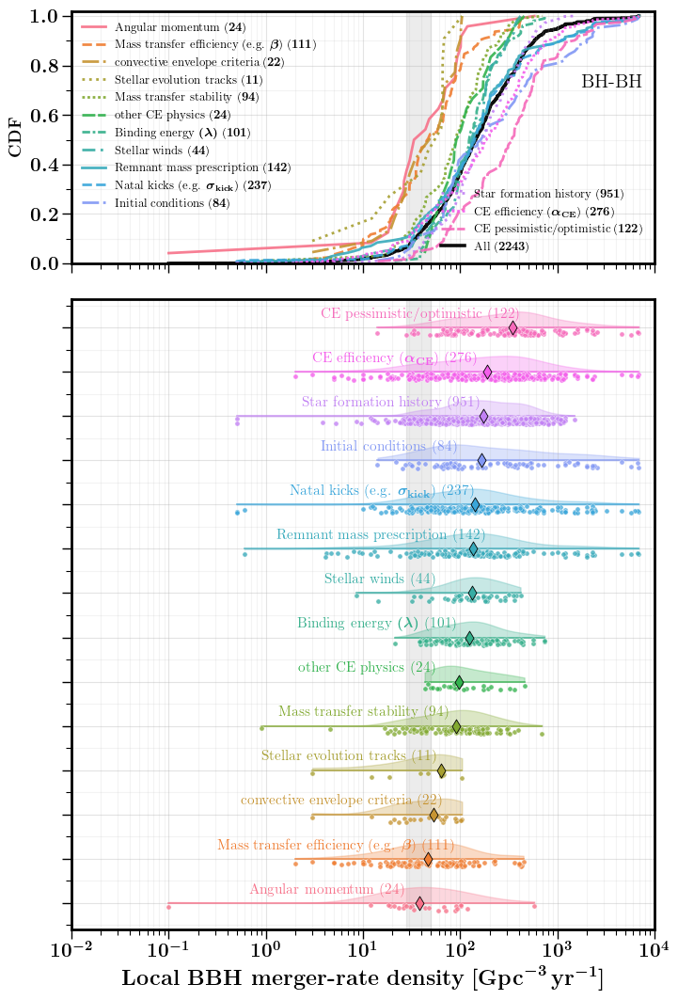

Doing it for DCOtype = NS-BH (BHNS)


/var/folders/07/v05tmc2s6p1f8qvmc216wrh80000gn/T/ipykernel_25726/3599630201.py:354: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved to ../figures/BHNS_rate_CDF_and_violin_by_parameter_family.pdf and ../figures/BHNS_rate_CDF_and_violin_by_parameter_family.png


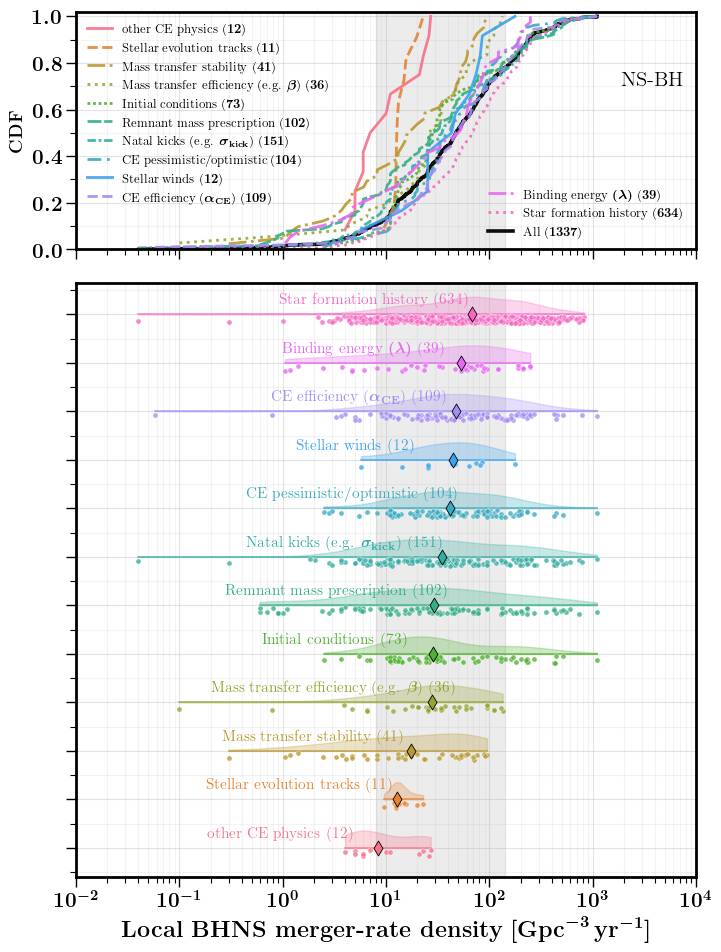

Doing it for DCOtype = NS-NS (BNS)


/var/folders/07/v05tmc2s6p1f8qvmc216wrh80000gn/T/ipykernel_25726/3599630201.py:354: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved to ../figures/BNS_rate_CDF_and_violin_by_parameter_family.pdf and ../figures/BNS_rate_CDF_and_violin_by_parameter_family.png


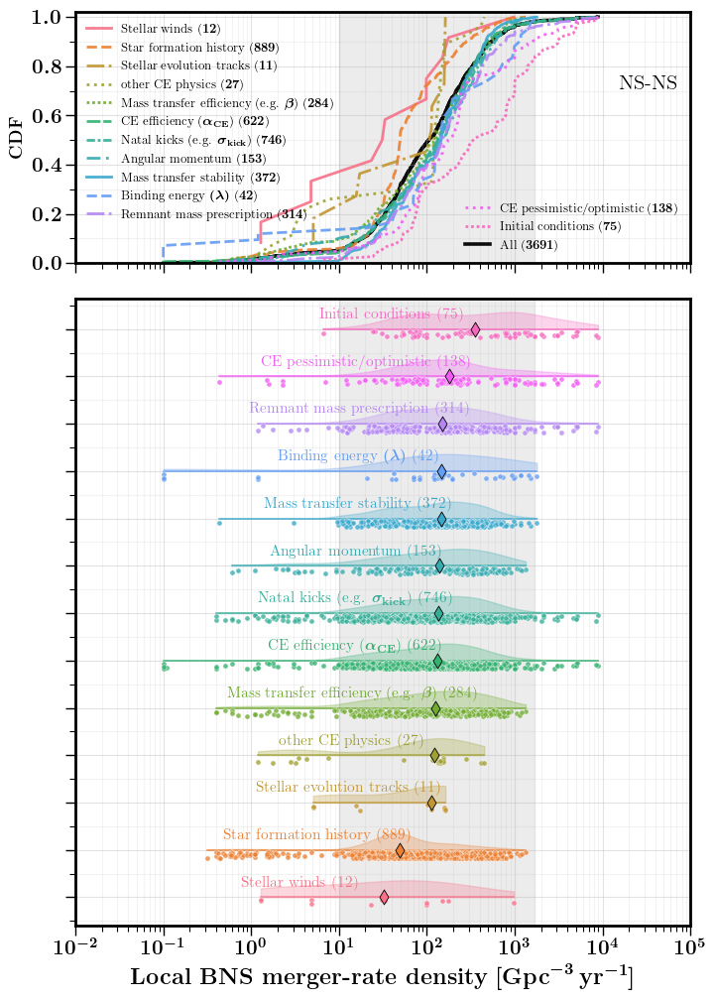

(<Figure size 800x1196 with 2 Axes>,
 (<Axes: ylabel='\\textbf{CDF}'>,
  <Axes: xlabel='$\\textbf{Local BNS merger-rate density}$ $[\\mathrm{Gpc}^{-3}\\,\\mathrm{yr}^{-1}]$'>),
                     study_key                    label  year  \
 4       Olejak_2021_Startrack     Olejak et al. (2021)  2021   
 5       Olejak_2021_Startrack     Olejak et al. (2021)  2021   
 46      Olejak_2022_Startrack     Olejak et al. (2022)  2022   
 47      Olejak_2022_Startrack     Olejak et al. (2022)  2022   
 48      Olejak_2022_Startrack     Olejak et al. (2022)  2022   
 ...                       ...                      ...   ...   
 15864  Chattaraj_2025_POSYDON  Chattaraj et al. (2025)  2025   
 15865  Chattaraj_2025_POSYDON  Chattaraj et al. (2025)  2025   
 15868  Chattaraj_2025_POSYDON  Chattaraj et al. (2025)  2025   
 15871  Chattaraj_2025_POSYDON  Chattaraj et al. (2025)  2025   
 15873  Chattaraj_2025_POSYDON  Chattaraj et al. (2025)  2025   
 
                            panel        

In [28]:
make_parameter_family_figure(
    "BH-BH",
    pts=pts,
    PANEL_ORDER=PANEL_ORDER,
    PANEL_DISPLAY_NAMES=PANEL_DISPLAY_NAMES,
    FIGURES_DIR=FIGURES_DIR,
    xmin=-2,
    xmax=4,
    boco_r0=None,
)



make_parameter_family_figure(
    "NS-BH",
    pts=pts,
    PANEL_ORDER=PANEL_ORDER,
    PANEL_DISPLAY_NAMES=PANEL_DISPLAY_NAMES,
    FIGURES_DIR=FIGURES_DIR,
    xmin=-2,
    xmax=4,
    boco_r0=None,
)


make_parameter_family_figure(
    "NS-NS",
    pts=pts,
    PANEL_ORDER=PANEL_ORDER,
    PANEL_DISPLAY_NAMES=PANEL_DISPLAY_NAMES,
    FIGURES_DIR=FIGURES_DIR,
    xmin=-2,
    xmax=5,
    boco_r0=None,
)

In [29]:
from itertools import cycle

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import LogLocator, MultipleLocator


LVK_BANDS = {
    "BH-BH": (27.5, 49.4),
    "NS-BH": (8.0, 140.0),
    "NS-NS": (10.0, 1700.0),
}

DCO_LABELS = {
    "BH-BH": "BBH",
    "NS-BH": "BHNS",
    "NS-NS": "BNS",
}


def make_code_rate_figure(
    DCOtype: str,
    data: pd.DataFrame,
    figures_dir,
    xmin: float = -1,
    xmax: float = 4,
    min_points_per_code: int = 10,
    boco_r0: float | None = None,
    save: bool = True,
    show: bool = True,
):
    """
    Make CDF and log-space violin plots of merger rates grouped by
    population-synthesis code.

    Parameters
    ----------
    DCOtype
        "BH-BH", "NS-BH", or "NS-NS".
    pts
        DataFrame containing at least:
        compact_object_type, rate, and code.
    figures_dir
        Directory in which to save the figures.
    xmin, xmax
        Axis limits in log10(rate).
    min_points_per_code
        Minimum number of rate entries required to display a code.
    boco_r0
        Optional comparison rate. Usually only relevant for BBHs.
    save
        Save PDF and PNG files.
    show
        Display the figure.

    Returns
    -------
    fig, (ax_cdf, ax), code_df
    """
    # --------------------------------------------------
    # Build clean DCO-specific dataframe
    # --------------------------------------------------
    DCO_ALIASES = {
        "BH-BH": ["BH-BH", "BBH"],
        "NS-BH": ["NS-BH", "BH-NS", "BHNS", "NSBH"],
        "NS-NS": ["NS-NS", "BNS"],
    }

    if DCOtype not in DCO_ALIASES:
        raise ValueError(
            f"Unknown DCOtype {DCOtype!r}. "
            f"Choose from {list(DCO_ALIASES)}."
        )

    dco_label = DCO_LABELS[DCOtype]
    LVK_LOW, LVK_HIGH = LVK_BANDS[DCOtype]

    required_columns = {
        "compact_object_type",
        "rate_Gpc3yr",
        "code",
    }

    missing = required_columns - set(data.columns)

    if missing:
        raise ValueError(
            f"Input dataframe is missing required columns: {sorted(missing)}"
        )

    print(f"Making code-rate figure for {DCOtype} ({dco_label})")

    code_df = data[
        data["compact_object_type"]
        .astype(str)
        .str.upper()
        .isin(DCO_ALIASES[DCOtype])
    ].copy()

    code_df["rate"] = pd.to_numeric(
        code_df["rate_Gpc3yr"],
        errors="coerce",
    )

    code_df = code_df[
        np.isfinite(code_df["rate"]) &
        (code_df["rate"] > 0)
    ].copy()

    code_df["code"] = (
        code_df["code"]
        .fillna("Unknown")
        .astype(str)
        .str.strip()
        .replace({
            "": "Unknown",
            "nan": "Unknown",
            "None": "Unknown",
        })
    )

    if code_df.empty:
        raise ValueError(
            f"No valid positive merger rates found for {DCOtype}."
        )

    # --------------------------------------------------
    # Keep only codes with enough entries
    # --------------------------------------------------
    code_counts = code_df["code"].value_counts()

    codes_to_plot = code_counts[
        code_counts >= min_points_per_code
    ].index.tolist()

    if not codes_to_plot:
        raise ValueError(
            f"No codes have at least {min_points_per_code} "
            f"entries for {DCOtype}."
        )

    dropped_codes = code_counts[
        code_counts < min_points_per_code
    ]

    print(
        f"Keeping {len(codes_to_plot)} codes with at least "
        f"{min_points_per_code} entries."
    )

    if not dropped_codes.empty:
        print("Excluded codes:")
        for code, count in dropped_codes.items():
            print(f"  {code}: {count} entries")

    # Sort codes by median merger rate
    code_order = (
        code_df[code_df["code"].isin(codes_to_plot)]
        .groupby("code")["rate"]
        .median()
        .sort_values()
        .index
        .tolist()
    )

    # Only retain entries associated with displayed codes.
    # This ensures that "All" represents the data shown in the figure.
    plot_df = code_df[
        code_df["code"].isin(code_order)
    ].copy()

    # --------------------------------------------------
    # Colors and line styles
    # --------------------------------------------------
    colors = sns.color_palette(
        "husl",
        n_colors=len(code_order),
    )
    code_to_color = dict(zip(code_order, colors))

    linestyles = [
        "-",
        "--",
        "-.",
        ":",
        (0, (1, 1)),
        (0, (5, 1)),
        (0, (3, 1, 1, 1)),
        (0, (5, 2, 1, 2)),
    ]

    linestyle_cycle = cycle(linestyles)

    code_to_linestyle = {
        code: next(linestyle_cycle)
        for code in code_order
    }

    # --------------------------------------------------
    # Create figure
    # --------------------------------------------------
    fig_h = max(
        6.5,
        0.72 * len(code_order) + 2.6,
    )

    fig, (ax_cdf, ax) = plt.subplots(
        nrows=2,
        ncols=1,
        figsize=(8.0, fig_h),
        sharex=False,
        gridspec_kw={
            "height_ratios": [1.0, 2.5],
            "hspace": 0.08,
        },
    )

    rng = np.random.default_rng(42)

    # --------------------------------------------------
    # Top panel: code-specific CDFs
    # --------------------------------------------------
    for code in code_order:
        sub = plot_df[
            plot_df["code"] == code
        ]

        rates = np.sort(sub["rate"].to_numpy())
        cdf = np.arange(1, len(rates) + 1) / len(rates)

        ax_cdf.plot(
            rates,
            cdf,
            lw=2.0,
            color=code_to_color[code],
            linestyle=code_to_linestyle[code],
            alpha=0.9,
            label=f"{code} ({len(rates)})",
        )

    # Combined CDF for all displayed codes
    all_rates = np.sort(plot_df["rate"].to_numpy())
    all_cdf = np.arange(1, len(all_rates) + 1) / len(all_rates)

    ax_cdf.plot(
        all_rates,
        all_cdf,
        lw=2.6,
        color="black",
        alpha=0.95,
        zorder=2,
        label=f"All ({len(all_rates)})",
    )

    # Observational interval
    ax_cdf.axvspan(
        LVK_LOW,
        LVK_HIGH,
        color="0.5",
        alpha=0.15,
        zorder=0,
        label="LVK interval",
    )

    # Optional comparison rate
    if boco_r0 is not None:
        ax_cdf.axvline(
            boco_r0,
            color="0.5",
            ls=":",
            lw=1,
            zorder=1,
        )

    ax_cdf.set_xscale("log")
    ax_cdf.set_xlim(10**xmin, 10**xmax)
    ax_cdf.set_ylim(0, 1.02)

    ax_cdf.xaxis.set_major_locator(
        LogLocator(base=10)
    )
    ax_cdf.xaxis.set_minor_locator(
        LogLocator(
            base=10,
            subs=np.arange(2, 10),
        )
    )

    ax_cdf.yaxis.set_major_locator(
        MultipleLocator(0.2)
    )
    ax_cdf.yaxis.set_minor_locator(
        MultipleLocator(0.1)
    )

    ax_cdf.set_ylabel(
        r"\textbf{CDF}",
        fontsize=13,
    )

    ax_cdf.tick_params(labelbottom=False)

    # DCO type in upper-right corner
    ax_cdf.text(
        0.97,
        0.75,
        DCOtype,
        transform=ax_cdf.transAxes,
        ha="right",
        va="top",
        fontsize=15,
        fontweight="bold",
        zorder=100,
    )

    # --------------------------------------------------
    # Split legend into two columns/locations
    # --------------------------------------------------
    handles, labels = ax_cdf.get_legend_handles_labels()

    mid = int(np.ceil(len(handles) / 2))

    leg1 = ax_cdf.legend(
        handles[:mid],
        labels[:mid],
        loc="upper left",
        frameon=False,
        fontsize=10.5,
    )

    ax_cdf.legend(
        handles[mid:],
        labels[mid:],
        loc="lower right",
        frameon=False,
        fontsize=10.5,
    )

    ax_cdf.add_artist(leg1)

    # --------------------------------------------------
    # Bottom panel: log-space violins
    # --------------------------------------------------
    for i, code in enumerate(code_order):
        sub = plot_df[
            plot_df["code"] == code
        ]

        rates = sub["rate"].to_numpy()
        x = np.log10(rates)

        color = code_to_color[code]

        if len(x) >= 3:
            parts = ax.violinplot(
                [x],
                positions=[i],
                vert=False,
                widths=0.72,
                showmeans=False,
                showmedians=False,
                showextrema=False,
            )

            for body in parts["bodies"]:
                body.set_facecolor(color)
                body.set_edgecolor(color)
                body.set_alpha(0.28)
                body.set_zorder(1)

                # Retain only the upper half of the violin
                path = body.get_paths()[0]
                vertices = path.vertices
                vertices[:, 1] = np.maximum(
                    vertices[:, 1],
                    i,
                )

        jitter = rng.uniform(
            -0.18,
            -0.04,
            len(x),
        )

        ax.scatter(
            x,
            i + jitter,
            s=14,
            alpha=0.78,
            color=color,
            edgecolor="white",
            linewidth=0.35,
            zorder=3,
        )

        median_x = np.median(x)

        ax.scatter(
            median_x,
            i,
            marker="d",
            s=58,
            facecolor=color,
            edgecolor="black",
            linewidth=0.6,
            zorder=4,
        )

        ax.plot(
            [np.min(x), np.max(x)],
            [i, i],
            lw=1.2,
            color=color,
            alpha=0.75,
            zorder=2,
        )

        label_x = median_x + 0.65

        ax.text(
            label_x,
            i + 0.25,
            f"{code} ({len(x)})",
            color=color,
            fontsize=11,
            fontweight="bold",
            va="center",
            ha="left",
        )

    # Observational region in log10 space
    ax.axvspan(
        np.log10(LVK_LOW),
        np.log10(LVK_HIGH),
        color="0.5",
        alpha=0.15,
        zorder=0,
    )

    if boco_r0 is not None:
        ax.axvline(
            np.log10(boco_r0),
            color="0.5",
            ls=":",
            lw=1,
            zorder=1,
        )

    ax.set_yticks(np.arange(len(code_order)))
    ax.set_yticklabels([""] * len(code_order))
    ax.set_ylim(
        -0.6,
        len(code_order) - 0.35,
    )

    # --------------------------------------------------
    # Bottom logarithmic-rate axis
    # --------------------------------------------------
    ax.set_xlim(xmin, xmax)

    major_ticks = np.arange(
        xmin,
        xmax + 1,
    )

    ax.set_xticks(major_ticks)
    ax.set_xticklabels([
        rf"$10^{{{int(t)}}}$"
        for t in major_ticks
    ])

    minor_ticks = []

    for decade in range(xmin, xmax):
        minor_ticks.extend(
            decade + np.log10(np.arange(2, 10))
        )

    ax.set_xticks(
        minor_ticks,
        minor=True,
    )

    ax.set_xlabel(
        rf"$\textbf{{Local {dco_label} merger-rate density}}$ "
        r"$[\mathrm{Gpc}^{-3}\,\mathrm{yr}^{-1}]$",
        fontsize=17,
    )

    ax.yaxis.set_minor_locator(
        MultipleLocator(0.5)
    )

    # --------------------------------------------------
    # Grid and tick styling
    # --------------------------------------------------
    for axis in (ax_cdf, ax):
        axis.grid(
            which="major",
            axis="both",
            alpha=0.35,
        )
        axis.grid(
            which="minor",
            axis="both",
            alpha=0.15,
        )

        axis.tick_params(
            axis="both",
            which="major",
            length=7,
            width=1.0,
            labelsize=15,
        )
        axis.tick_params(
            axis="both",
            which="minor",
            length=4.5,
            width=0.8,
        )

    plt.tight_layout()

    # --------------------------------------------------
    # Save
    # --------------------------------------------------
    if save:
        base = (
            figures_dir
            / f"{dco_label}_rate_CDF_and_violin_by_population_synthesis_code"
        )

        fig.savefig(
            base.with_suffix(".pdf"),
            bbox_inches="tight",
        )

        fig.savefig(
            base.with_suffix(".png"),
            dpi=300,
            bbox_inches="tight",
        )

        print(f"Saved {base.with_suffix('.pdf')}")
        print(f"Saved {base.with_suffix('.png')}")

    if show:
        plt.show()

    return fig, (ax_cdf, ax), plot_df

Making code-rate figure for BH-BH (BBH)
Keeping 11 codes with at least 10 entries.
Excluded codes:
  B-POP: 9 entries
  Brussels: 6 entries
  Scenario Machine: 1 entries
  binary c: 1 entries


/var/folders/07/v05tmc2s6p1f8qvmc216wrh80000gn/T/ipykernel_25726/1639403821.py:524: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved ../figures/BBH_rate_CDF_and_violin_by_population_synthesis_code.pdf
Saved ../figures/BBH_rate_CDF_and_violin_by_population_synthesis_code.png


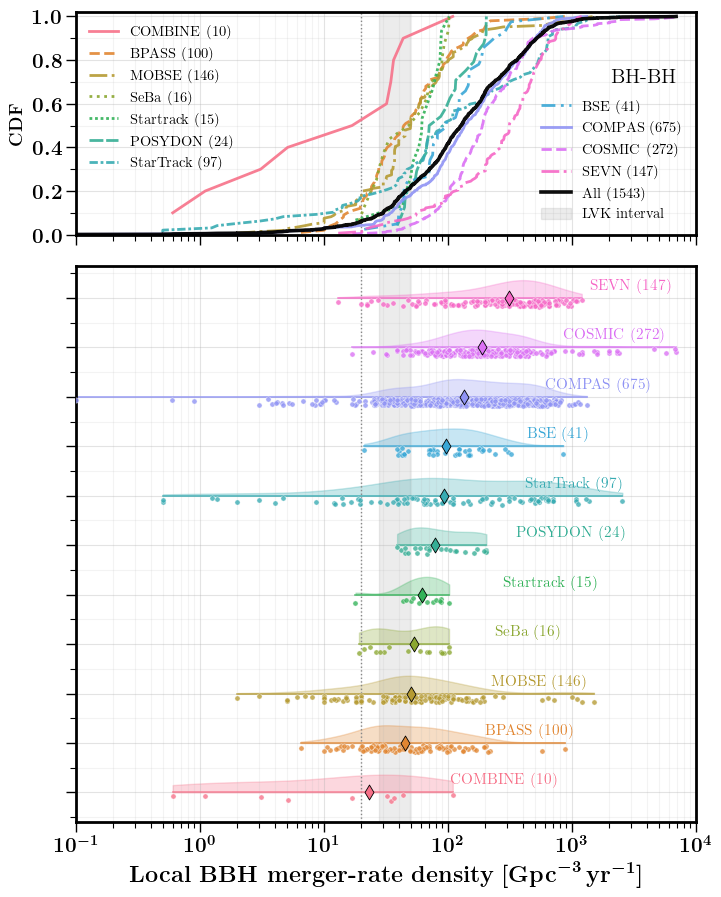

Making code-rate figure for NS-BH (BHNS)
Keeping 11 codes with at least 10 entries.
Excluded codes:
  MOBSE + EAGLE: 1 entries


/var/folders/07/v05tmc2s6p1f8qvmc216wrh80000gn/T/ipykernel_25726/1639403821.py:524: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved ../figures/BHNS_rate_CDF_and_violin_by_population_synthesis_code.pdf
Saved ../figures/BHNS_rate_CDF_and_violin_by_population_synthesis_code.png


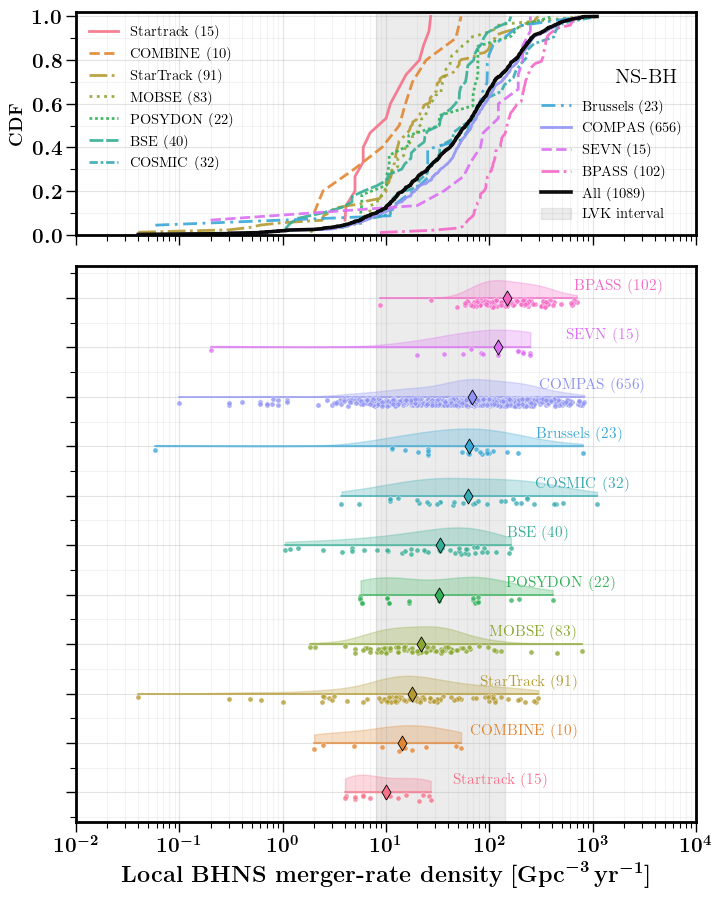

Making code-rate figure for NS-NS (BNS)
Keeping 11 codes with at least 10 entries.
Excluded codes:
  Scenario Machine: 2 entries


/var/folders/07/v05tmc2s6p1f8qvmc216wrh80000gn/T/ipykernel_25726/1639403821.py:524: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved ../figures/BNS_rate_CDF_and_violin_by_population_synthesis_code.pdf
Saved ../figures/BNS_rate_CDF_and_violin_by_population_synthesis_code.png


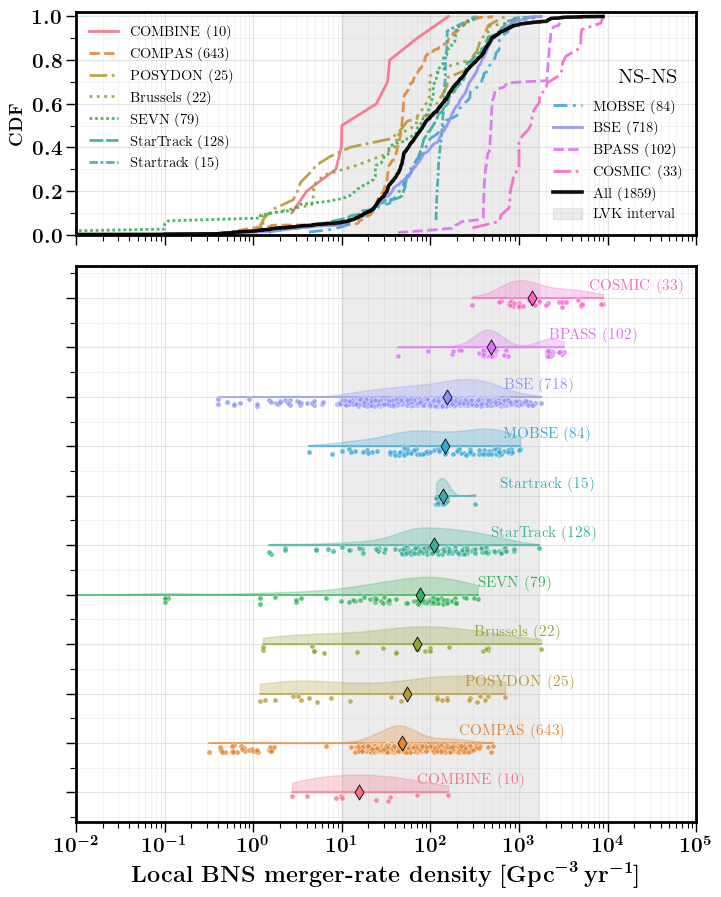

In [30]:
df = pd.read_csv(
    DATA_DIR / "isolated-binary-evolution.csv",
    dtype=str,
).fillna("")

# --------------------------------------------------
# Standardize compact-object labels
# --------------------------------------------------

# DCO_LABEL_MAP = {
#     "BBH": "BBH",
#     "BH-BH": "BBH",
#     "BHBH": "BBH",

#     "BHNS": "BHNS",
#     "BH-NS": "BHNS",
#     "NS-BH": "BHNS",
#     "NSBH": "BHNS",

#     "BNS": "BNS",
#     "NS-NS": "BNS",
#     "NSNS": "BNS",
# }

# df["DCO_type"] = (
#     df["compact_object_type"]
#     .str.upper()
#     .str.strip()
#     .map(DCO_LABEL_MAP)
# )




fig, axes, bbh_code_df = make_code_rate_figure(
    DCOtype="BH-BH",
    data=df,
    figures_dir=FIGURES_DIR,
    xmin=-1,
    xmax=4,
    min_points_per_code=10,
    boco_r0=BOCO_R0,
)

fig, axes, bhns_code_df = make_code_rate_figure(
    DCOtype="NS-BH",
    data=df,
    figures_dir=FIGURES_DIR,
    xmin=-2,
    xmax=4,
    min_points_per_code=10,
    boco_r0=None,
)

fig, axes, bns_code_df = make_code_rate_figure(
    DCOtype="NS-NS",
    data=df,
    figures_dir=FIGURES_DIR,
    xmin=-2,
    xmax=5,
    min_points_per_code=10,
    boco_r0=None,
)

In [31]:
# print(df.columns.tolist())